# Hotel Guest Segmentation

This project explores customer segmentation for Hotel H, an independent hotel located in Lisbon, Portugal, part of hotel chain C. Using the CRISP-DM methodology, this analysis aims to uncover meaningful customer segments, providing valuable insights to enhance marketing strategies, optimize services, and improve overall guest experience. This structured approach ensures a data-driven foundation for addressing the business problem.

# 1. Business Understanding

## Background  

Hotel chain C initially operated four hotels until 2015, after which it expanded through acquisitions. With this growth, the board decided to increase investment in marketing. However, it was not until 2018 that the hotel chain established a dedicated marketing department and appointed a new marketing manager, A.  

Upon reviewing the existing customer segmentation strategy significant limitations were identified, for instance the segmentation was based solely on the sales origin of customers and did not consider other key factors such as:  

- **Geographic characteristics** (e.g., country of origin)  
- **Demographic characteristics** (e.g., age)  
- **Behavioral characteristics** (e.g., frequency of stays)  

Although the previous segmentation strategy is valid, it can be highly inefficient and biased, as it fails to consider key factors that significantly influence customer behavior and purchasing patterns. Overlooking these aspects makes it challenging to develop effective marketing strategies for both attracting new customers and retaining existing ones.  

## Business Objectives

Our primary business objective is **to enhance customer segmentation to improve conversion rates**. To achieve this, our team will conduct a comprehensive analysis of Hotel H’s customer data, focusing on two key sub-objectives:  

### Sub-Objectives (SBOs)  
- **SBO1:** Develop a **more precise and effective customer segmentation model** that surpasses the company’s current market segments.  
- **SBO2:** Provide **actionable marketing recommendations** aligned with the newly created segments to guide Hotel H’s marketing strategy.  

By leveraging this **data-driven customer segmentation**, the hotel chain can refine its marketing strategy, allocate resources efficiently, and ultimately drive revenue growth.

## Data Mining Goals

Besides the business objectives, this customer segmentation approach also aims to achieve several key data mining goals:  

- **DMG1:** Develop a **customer segmentation model** consisting of approximately **4 to 6 well-defined and meaningful segments**.  
- **DMG2:** Ensure customer segments are **balanced in size and distribution** to maintain analytical reliability and marketing applicability.  
- **DMG3:** Implement a **clustering algorithm** that is **computationally efficient, easy to deploy, and scalable** for future data updates.  
- **DMG4:** Ensure the **customer segmentation model is interpretable and actionable**, allowing the marketing and sales teams to easily understand and apply the insights.  
- **DMG5:** Leverage **key customer characteristics**—such as booking behaviour, spending patterns, and demographics—to **enhance segmentation reliability** and ensure relevance to business objectives.  


# 2. Data Understanding

## 2.1. Import Libraries

__`Step 1`__ Load the required libraries.

In [1]:
# Data Understanding
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import itertools
import squarify

# Data Preparation
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from scipy.stats import johnsonsu
from sklearn.preprocessing import PowerTransformer

# Modelling
import matplotlib.cm as cm
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.manifold import TSNE
from tabulate import tabulate
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram

## 2.2. Data Integration

__`Step 2`__ Load the dataset into Python. (Notice that the Jupyter Notebook needs to be stored in the same folder as the dataset).

In [2]:
# Create a path to where the csv is stored.
path = "data/Case1_HotelCustomerSegmentation.csv"

# Load the dataset. 
df = pd.read_csv(path, sep=";")

### 2.2.1. Data Description

`ID` : Customer ID. <br>
`Nationality` : Nationality of the customer in ISO 3166-1 (Alpha 3) format. <br>
`Age`: The age of the customer. <br>
`DaysSinceCreation` : Number of elapsed days since the customer was created. <br>
`NameHash` : Hash of the customer's name. <br>
`DocIDHash` : Hash of the customer’s personal document identification number (usually a passport or ID card). <br>
`AverageLeadTime` : Average number of days before arrival date the customer makes bookings. <br>
`LodgingRevenue` : Total amount of lodging revenue paid by the customer so far <br>
`OtherRevenue` : Total amount of other revenue (e.g., food & beverage, spa, etc.) paid by the customer so far. <br>
`BookingsCanceled` : Number of bookings the customer made but subsequently canceled. <br>
`BookingsNoShowed` : Number of bookings the customer made but subsequently made a "no-show". <br>
`BookingsCheckedin` : Number of bookings the customer made, which actually ended up staying. <br>
`PersonNights` : Total person/nights the customer has stayed at the hotel so far. Persons/Nights are the sum of Adults and Children in each booking, multiplied by the number of Nights (Length-of-stay) of the booking. <br>
`RoomNights`: Total of room/nights the customer has stayed at the hotel so far. Room/Nights are the multiplication of the number of
rooms of each booking by the the number of Nights (Length-ofstay) of the booking. <br>
`DistributionChannel` : Distribution channel normally used by the customer to make bookings at the hotel. <br>
`MarketSegment` : Current market segment of the customer. <br>
`SRHighFloor` : Indication if the customer usually asks for a room in a higher floor (0: No, 1: Yes). <br>
`SRLowFloor` : Indication if the customer usually asks for a room in a lower floor (0: No, 1: Yes). <br>
`SRAccessibleRoom` : Indication if the customer usually asks for an accessible room (0: No, 1: Yes). <br>
`SRMediumFloor` : Indication if the customer usually asks for a room in a middle floor (0: No, 1: Yes). <br>
`SRBathtub` : Indication if the customer usually asks for a room with a bathtub (0: No, 1: Yes). <br>
`SRShower` : Indication if the customer usually asks for a room with a shower (0: No, 1: Yes). <br>
`SRCrib` : Indication if the customer usually asks for a crib (0: No, 1: Yes). <br>
`SRKingSizeBed` : Indication if the customer usually asks for a room with a king size bed (0: No, 1: Yes). <br>
`SRTwinBed` : Indication if the customer usually asks for a room with a twin bed (0: No, 1: Yes). <br>
`SRNearElevator` : Indication if the customer usually asks for a room near the elevator (0: No, 1: Yes). <br>
`SRAwayFromElevator` : Indication if the customer usually asks for a room away from the elevator (0: No, 1: Yes). <br>
`SRNoAlcoholInMiniBar` : Indication if the customer usually asks for a room with no alcohol in the mini bar (0: No, 1: Yes). <br>
`SRQuietRoom` : Indication if the customer usually asks for a room away from the noise (0: No, 1: Yes). 

## 2.3. Data Content

__`Step 3`__ Checking the top 5 rows of the dataset. 

In [3]:
df.head()

,ID,Nationality,Age,DaysSinceCreation,NameHash,DocIDHash,AverageLeadTime,LodgingRevenue,OtherRevenue,BookingsCanceled,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
0,1,PRT,52.0,440,0x2C371FD6CE12936774A139FD7430C624F1C4D5109CE6...,0x434FD3D59469C73AFEA087017FAF8CA2296493AEABDE...,59,292.0,82.3,1,...,0,0,0,0,0,0,0,0,0,0
1,2,PRT,NaN,1385,0x198CDB98BF37B6E23F9548C56A88B00912D65A9AA0D6...,0xE3B0C44298FC1C149AFBF4C8996FB92427AE41E4649B...,61,280.0,53.0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,DEU,32.0,1385,0xDA46E62F66936284DF2844EC4FC542D0DAD780C0EE0C...,0x27F5DF762CCDA622C752CCDA45794923BED9F1B66300...,0,0.0,0.0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,FRA,61.0,1385,0xC45D4CD22C58FDC5FD0F95315F6EFA5A6E7149187D49...,0x8E59572913BB9B1E6CAA12FA2C8B7BF387B1D1F3432E...,93,240.0,60.0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,FRA,52.0,1385,0xD2E3D5BFCA141865669F98D64CDA85AD04DEFF47F8A0...,0x42BDEE0E05A9441C94147076EDDCC47E604DA5447DD4...,0,0.0,0.0,0,...,0,0,0,0,0,0,0,0,0,0


__`Step 4`__ Checking the number of rows and columns of the dataset.

In [4]:
df.shape

(111733, 29)

__`Step 5`__ Checking the features data types and non-missing observations.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111733 entries, 0 to 111732
Data columns (total 29 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID                    111733 non-null  int64  
 1   Nationality           111733 non-null  object 
 2   Age                   107561 non-null  float64
 3   DaysSinceCreation     111733 non-null  int64  
 4   NameHash              111733 non-null  object 
 5   DocIDHash             110732 non-null  object 
 6   AverageLeadTime       111733 non-null  int64  
 7   LodgingRevenue        111733 non-null  float64
 8   OtherRevenue          111733 non-null  float64
 9   BookingsCanceled      111733 non-null  int64  
 10  BookingsNoShowed      111733 non-null  int64  
 11  BookingsCheckedIn     111733 non-null  int64  
 12  PersonsNights         111733 non-null  int64  
 13  RoomNights            111733 non-null  int64  
 14  DistributionChannel   111733 non-null  object 
 15  

__`Step 5.1`__ Checking in a direct way the total number of missing values in the dataset.

In [6]:
df.isna().sum()

ID                         0
Nationality                0
Age                     4172
DaysSinceCreation          0
NameHash                   0
DocIDHash               1001
AverageLeadTime            0
LodgingRevenue             0
OtherRevenue               0
BookingsCanceled           0
BookingsNoShowed           0
BookingsCheckedIn          0
PersonsNights              0
RoomNights                 0
DistributionChannel        0
MarketSegment              0
SRHighFloor                0
SRLowFloor                 0
SRAccessibleRoom           0
SRMediumFloor              0
SRBathtub                  0
SRShower                   0
SRCrib                     0
SRKingSizeBed              0
SRTwinBed                  0
SRNearElevator             0
SRAwayFromElevator         0
SRNoAlcoholInMiniBar       0
SRQuietRoom                0
dtype: int64

From this initial and simple analysis of the data, several insights can be drawn:  

- **Dataset Size:** The dataset contains **111,733 observations**, making certain clustering algorithms, such as **Hierarchical Clustering, an undesirable choice**. Given the large number of data points, the algorithm would need to compute an extensive distance matrix, which is not only computationally expensive but also time-consuming.  

- **Feature Dimensionality:** With **29 features**, the dataset presents a high-dimensional space, which can lead to the **curse of dimensionality**. As the number of dimensions increases, the data becomes sparser, potentially affecting the performance of clustering algorithms and distance-based models.  

- **Data Types & Feature Interpretation:** While the data types are correctly assigned, special attention is needed for the features related to **Special Requests**. Despite being stored as integers, these variables represent **binary categorical features**, meaning they should be treated as categorical data. Directly computing distances with these variables could lead to misleading results.  

- **Missing Data:** Most features contain complete information, with the exception of **`Age`** and **`DocIDHash`**, which have **4172** and **1001** missing values, respectively. However, a more in-depth analysis is required to detect other forms of missing information, such as **‘Unknown’** categories in categorical features, which might indicate hidden missing values.  


## 2.4. Descriptive Statistics

__`Step 6`__ Computing descriptive statistic for the numerical features.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,111733.0,55867.000000,32254.683151,1.0,27934.0,55867.0,83800.0,111733.00
Age,107561.0,45.639191,17.244952,-10.0,33.0,47.0,58.0,123.00
DaysSinceCreation,111733.0,595.026599,374.657382,36.0,288.0,522.0,889.0,1385.00
AverageLeadTime,111733.0,60.833147,85.115320,-1.0,0.0,21.0,95.0,588.00
LodgingRevenue,111733.0,283.851283,379.131556,0.0,0.0,208.0,393.3,21781.00
OtherRevenue,111733.0,64.682802,123.580715,0.0,0.0,31.0,84.0,8859.25
BookingsCanceled,111733.0,0.002282,0.080631,0.0,0.0,0.0,0.0,15.00
BookingsNoShowed,111733.0,0.000600,0.028217,0.0,0.0,0.0,0.0,3.00
BookingsCheckedIn,111733.0,0.737607,0.730889,0.0,0.0,1.0,1.0,76.00
PersonsNights,111733.0,4.328318,4.630739,0.0,0.0,4.0,6.0,116.00


From this analysis we can conclude:

- While Age of the customers seems to be correct for the majority of the cases, there seems to be a clear problem with some ages, for example the maximum value is 123 years old, but the oldest person to ever live in planet Earth was **Jeanne Calment** that died age 122, so it is clearly an invalid value.
- Due to gaps between the values in the 75% percentile and the maximum value we can say that all the numerical features (excluding the SR features, since as previously discussed those are not numerical) present some sort of outliers that would require further analysis and treatment.
- There are negative values in `Age` and `AverageLeadTime` which is clearly and error and need treatment.
- There are no new customers to the company in the provided dataset, the most recent customer in the data is a customer that made a booking 36 days prior to the collection of data.
- It is made clear that customers in the dataset normally show up to their reservation, as 75% of the customers did not cancel there reservation or did not show to the booking that was made.
- The Special request related variables seem to be coherent, as the minimum is 0 and the maximum 1, respecting the rule of being a binary variable. The special request that seems the most common is KingSizeBed with at least 25% of the customers asking for it.

__`Step 6.1`__ Compute descriptive statistics for the categorical features.

In [8]:
df.describe(include='O')

,Nationality,NameHash,DocIDHash,DistributionChannel,MarketSegment
count,111733,111733,110732,111733,111733
unique,199,107584,103480,4,7
top,FRA,0x15A713CE687991691A18F6CDC56ABE24979C73CF5D51...,0xE3B0C44298FC1C149AFBF4C8996FB92427AE41E4649B...,Travel Agent/Operator,Other
freq,16516,75,3032,91019,63680


From this analysis we can conclude:

- Customers from the database are from 199 distinct countries, with France being the top country clientele with 16516 customers.
- There are some customers that have the same `NameHash` meaning that there are customers with the same name or duplicated rows in the dataset.
- By it's metadata definition, the feature `DocIDHash` should present unique values for every single customer. Nonetheless from the 110732 non-null values that we have there are only 103480 unique values, which indicate the presence of noise in data, that can be translated into duplicated rows.
- Overall `NameHash` and `DocIDHash` are two features very redundant for the customer segmentation, since they possess very high cardinalities and are categorical features which are not good to be used in the clustering algorithms. For that reason this variable might be discarted in the Data Preparation stage of this initiative.
- The variable `DistributionChannel` has 4 unique values, making it very easy to use for clustering profiling. The most frequent channel is Travel Agent/Operator.
- Concerning the previous `MarketSegment` made by the comapny H, there solution had 7 different clusters, with the ones that have more customers being the cluster of "Other" clients that has around 60% of the customers in it. This implies that the previous clustering segmentation is not a very good one, because it has a huge portion of the customers in a cluster that says very few things about those customers, so the marketing campaigns that would be developed from it, wouldn't be the best ones as they would be very generic.

## 2.5. Missing values analysis

__`Step 7`__ Checking if there are customers that have missing values in both columns previously identified with missing data.

In [9]:
len(df[df[['DocIDHash', 'Age']].isnull().all(axis=1)])

1001

__`Step 8`__ Checking hwo many rows have at least 1 missing value.

In [10]:
len(df[df[['DocIDHash', 'Age']].isnull().any(axis=1)])

4172

- We can see that the customers that have a missing value in `DocIDHash` also have a missing value in `Age`. Meaning that this missingness is not necessary a random one. The relationship of this missingness is missing not at random. 
- Additionally it was made clear that the total number of missing values equals to the number of missing values in variable `Age`.

## 2.6. Incoherences

__`Step 9`__ Setting `ID` as index.

In [11]:
# Setting ID as index
df.set_index('ID', inplace=True)

# Checking the change in the dataset
df.head()

,Nationality,Age,DaysSinceCreation,NameHash,DocIDHash,AverageLeadTime,LodgingRevenue,OtherRevenue,BookingsCanceled,BookingsNoShowed,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
ID,,,,,,,,,,,,,,,,,,,,,
1,PRT,52.0,440,0x2C371FD6CE12936774A139FD7430C624F1C4D5109CE6...,0x434FD3D59469C73AFEA087017FAF8CA2296493AEABDE...,59,292.0,82.3,1,0,...,0,0,0,0,0,0,0,0,0,0
2,PRT,NaN,1385,0x198CDB98BF37B6E23F9548C56A88B00912D65A9AA0D6...,0xE3B0C44298FC1C149AFBF4C8996FB92427AE41E4649B...,61,280.0,53.0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,DEU,32.0,1385,0xDA46E62F66936284DF2844EC4FC542D0DAD780C0EE0C...,0x27F5DF762CCDA622C752CCDA45794923BED9F1B66300...,0,0.0,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,FRA,61.0,1385,0xC45D4CD22C58FDC5FD0F95315F6EFA5A6E7149187D49...,0x8E59572913BB9B1E6CAA12FA2C8B7BF387B1D1F3432E...,93,240.0,60.0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,FRA,52.0,1385,0xD2E3D5BFCA141865669F98D64CDA85AD04DEFF47F8A0...,0x42BDEE0E05A9441C94147076EDDCC47E604DA5447DD4...,0,0.0,0.0,0,0,...,0,0,0,0,0,0,0,0,0,0


This process is done because as the ID is unique all customers have different values, meaning that this feature has no capacity to segment customers since all of them from this feature are different. Also we need use the ID as an index of the dataset because otherwise we wouldn't be capable of identifying duplicated rows.

__`Step 10`__ Checking for duplicated rows in the data.

In [12]:
df[df.duplicated(subset=["NameHash", "DocIDHash", "Nationality"])]

,Nationality,Age,DaysSinceCreation,NameHash,DocIDHash,AverageLeadTime,LodgingRevenue,OtherRevenue,BookingsCanceled,BookingsNoShowed,...,SRMediumFloor,SRBathtub,SRShower,SRCrib,SRKingSizeBed,SRTwinBed,SRNearElevator,SRAwayFromElevator,SRNoAlcoholInMiniBar,SRQuietRoom
ID,,,,,,,,,,,,,,,,,,,,,
448,AGO,53.0,1376,0x05842189D4980DE3E463F1C49202001E6D433F246F48...,0x2A84DA7C5E0703A07903A23A1077A93D01F041FA3F50...,0,75.0,26.00,0,0,...,0,0,0,0,0,0,0,0,0,0
497,AGO,19.0,1371,0xCA45507F6EEBD2BF107402EB5EF7A82802CB8501F2D8...,0xD340880F2B5040688D70EA73262D977556D84542A66D...,0,0.0,0.00,0,0,...,0,0,0,0,0,0,0,0,0,0
574,FRA,39.0,1366,0x151534153AD90C917F2ECC4969626BEA37E66E0F85C3...,0xBDF406844F5C6F19839DEA4A9EF9B5496B5D4E2D07CC...,20,146.0,19.00,0,0,...,0,0,0,0,0,0,0,0,0,0
595,ROU,38.0,1365,0x71AD7B2E07CAD82195B968B7CDD7961EC953760899B5...,0x9CD129744684370C750190DB02D767653BB96C8119B3...,0,0.0,0.00,0,0,...,0,0,0,0,1,0,0,0,0,0
623,PRT,45.0,1364,0xA572ACFD6ED984560AD56A76021496F96C48CB03BA54...,0x8D9B0172FF7BC4BAFFF32BABC1C54FCA1207D33C2DB4...,0,493.0,46.00,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111323,LUX,8.0,40,0x855D1540E591F6640709E8BB6F6BE26F04EBEBD3510F...,0x6CF7256E1B20F60DA11D590BF376C205A10D23FA68B1...,0,0.0,0.00,0,0,...,0,0,0,0,0,0,0,0,0,0
111344,FRA,75.0,40,0x1441D0635E3493605030DEA783DAC8B924A3EE9A7298...,0x46AF3DF631BB4FA041D897E43A1679FD8F77E3793B6C...,0,0.0,0.00,0,0,...,0,0,0,0,0,1,0,0,0,0
111352,FRA,54.0,39,0x05ACC2AEB73F8A40BCDF90175DE9935D36F8D6632E60...,0x769F23C18265E2D8B03CE2EC6F6124C5BD000EE63198...,0,0.0,0.00,0,0,...,0,0,0,0,0,1,0,0,0,0


The variables `NameHash`, `DocIDHash` and `Nationality` were considered the ones to be used for checking duplicates, because:

1. `DocIDHash` should have unique values for each client
2. `NameHash` should be to some sort different from people, and using it alongside with `DocIDHash` ensures that even if there are people that have the same name they shouldn't have the same `DocIDHash`.
3. `Nationality` ensures that we allow people that might have the same but are from different nationalities to not be considered as the same person.

With this query we identified 3319 duplicated customers in the dataset that are removed in the next step

__`Step 10.1`__ Remove the duplicated rows from the dataset.

In [13]:
df = df.drop_duplicates(subset=["NameHash", "DocIDHash", "Nationality"], keep="first")

Duplicate rows should be removed as they represent the same customers appearing multiple times. Analyzing the same customer more than once is unnecessary and could introduce bias into clustering algorithms, potentially distorting the results. Removing duplicates ensures a more accurate and reliable analysis.

__`Step 11`__ Checking if there are invalid nationalities.

In [14]:
# Create a list of all country codes
all_country_codes = ['AFG', 'ALB', 'AND', 'DZA', 'ASM', 'AGO', 'AIA', 'ATA', 'ATG', 'ARG', 'ARM', 'ABW', 'AUS', 'AUT', 'AZE', 'BHS', 'BHR', 'BGD', 'BRB', 'BLR', 'BEL', 'BLZ', 
                     'BEN', 'BMU', 'BTN', 'BOL', 'BES', 'BIH', 'BWA', 'BVT', 'BRA', 'IOT', 'BRN', 'BGR', 'BFA', 'BDI', 'CPV', 'KHM', 'CMR', 'CAN', 'CYM', 'CAF', 'TCD', 'CHL', 
                     'CHN', 'CXR', 'CCK', 'COL', 'COM', 'COD', 'COG', 'COK', 'CRI', 'HRV', 'CUB', 'CUW', 'CYP', 'CZE', 'CIV', 'DNK', 'DJI', 'DMA', 'DOM', 'ECU', 'EGY', 'SLV', 
                     'GNQ', 'ERI', 'EST', 'SWZ', 'ETH', 'FLK', 'FRO', 'FJI', 'FIN', 'FRA', 'GUF', 'PYF', 'ATF', 'GAB', 'GMB', 'GEO', 'DEU', 'GHA', 'GIB', 'GRC', 'GRL', 'GRD', 
                     'GLP', 'GUM', 'GTM', 'GGY', 'GIN', 'GNB', 'GUY', 'HTI', 'HMD', 'VAT', 'HND', 'HKG', 'HUN', 'ISL', 'IND', 'IDN', 'IRN', 'IRQ', 'IRL', 'IMN', 'ISR', 'ITA', 
                     'JAM', 'JPN', 'JEY', 'JOR', 'KAZ', 'KEN', 'KIR', 'PRK', 'KOR', 'KWT', 'KGZ', 'LAO', 'LVA', 'LBN', 'LSO', 'LBR', 'LBY', 'LIE', 'LTU', 'LUX', 'MAC', 'MDG', 
                     'MWI', 'MYS', 'MDV', 'MLI', 'MLT', 'MHL', 'MTQ', 'MRT', 'MUS', 'MYT', 'MEX', 'FSM', 'MDA', 'MCO', 'MNG', 'MNE', 'MSR', 'MAR', 'MOZ', 'MMR', 'NAM', 'NRU', 
                     'NPL', 'NLD', 'NCL', 'NZL', 'NIC', 'NER', 'NGA', 'NIU', 'NFK', 'MNP', 'NOR', 'OMN', 'PAK', 'PLW', 'PSE', 'PAN', 'PNG', 'PRY', 'PER', 'PHL', 'PCN', 'POL', 
                     'PRT', 'PRI', 'QAT', 'MKD', 'ROU', 'RUS', 'RWA', 'REU', 'BLM', 'SHN', 'KNA', 'LCA', 'MAF', 'SPM', 'VCT', 'WSM', 'SMR', 'STP', 'SAU', 'SEN', 'SRB', 'SYC', 
                     'SLE', 'SGP', 'SXM', 'SVK', 'SVN', 'SLB', 'SOM', 'ZAF', 'SGS', 'SSD', 'ESP', 'LKA', 'SDN', 'SUR', 'SJM', 'SWE', 'CHE', 'SYR', 'TWN', 'TJK', 'TZA', 'THA', 
                     'TLS', 'TGO', 'TKL', 'TON', 'TTO', 'TUN', 'TUR', 'TKM', 'TCA', 'TUV', 'UGA', 'UKR', 'ARE', 'GBR', 'UMI', 'USA', 'URY', 'UZB', 'VUT', 'VEN', 'VNM', 'VGB', 
                     'VIR', 'WLF', 'ESH', 'YEM', 'ZMB', 'ZWE', 'ALA']

# Checking if there is any value of country code in the Nationality feature that does not correspond to a valid country.
df[~df['Nationality'].isin(all_country_codes)]['Nationality'].unique()

array(['TMP'], dtype=object)

All the values of Nationality are valid, the only one that is not is 'TMP'. Nonetheless, this does not represent a country that does not exist but it represents the East Timor in the old ISO 3166-1 alpha-3 country code, that changed to TLS in 2002. This will be accounted in the Data Preparation stage.

__`Step 12`__ Checking if there are any customers that did check-in but did not pay any lodging expenses.

In [15]:
len(df[(df['BookingsCheckedIn'] == 1) & (df['LodgingRevenue'] ==0)])

451

__`Step 12.1`__ Checking the customers that checked in once (and those that checked in more than once) and did not spend any money in lodging revenue or other revenue.

In [16]:
(len(df[(df['BookingsCheckedIn'] == 1) & (df['LodgingRevenue'] ==0) & (df['OtherRevenue'] == 0)]), 
len(df[(df['BookingsCheckedIn'] > 1) & (df['LodgingRevenue'] == 0) & (df['OtherRevenue'] == 0)]))

(268, 27)

__`Step 12.2`__ Checking the amount of customers that did more than 1 check-in but did not pay any lodging expenses.

In [17]:
len(df[(df['BookingsCheckedIn'] > 1) & (df['LodgingRevenue'] == 0)])

49

__`Step 12.3`__ Checking if there are any customers that did not do any check-in, but paid LodgingRevenue.

In [18]:
len(df[(df['BookingsCheckedIn'] == 0) & (df['LodgingRevenue'] != 0)])

1

__`Step 12.4`__ Checking if the previously identified customer also spent money on other revenue.

In [19]:
len(df[(df['BookingsCheckedIn'] == 0) & (df['LodgingRevenue'] != 0) & (df['OtherRevenue'] !=0)])

1

__`Step 12.5`__ Checking if there are customers that didn't check in, but did spend time in the hotel.

In [20]:
len(df[(df['BookingsCheckedIn'] == 0) & (df['PersonsNights'] != 0) & (df['RoomNights'] !=0)])

0

__`Step 12.6`__ Checking if there are customers that did check in, but didn't spend time in the hotel.

In [21]:
len(df[(df['BookingsCheckedIn'] != 0) & (df['PersonsNights'] == 0) & (df['RoomNights'] == 0)])

0

From these queries we can see that:

**Relevant Insights**

- There are 451 customers that did a Check-In but did not pay any Lodging Expenses. This might represent clients that at the current stage are still in the hotel, so they did not pay they bills as no check-out was done. From those customers 268 did not spend any money at the company.
- There are no persons that did not checked in but did spend time on the hotel or vice-versa.

**Incoherences**

- There are 27 customers that did more than 1 check-in and still did not spend any money on the company. (This is an issue as they should have paid at least there first stay).
- There are 49 customers that did more than 1 Check-In and did not pay any Lodging Expenses. This case poses a problem, because by making more than 1 Check-In it means that there are customers that did at least 1 Check-Out but did not pay any lodging expenses.
- There is 1 customer that did spend money on lodging revenue and additionally in other revenue, while it never was in the hotel. (while this could be possible - the person could be paying an initial value to book the reservation, it is very unlikely that it also paid money in other expenses).


__`Step 13`__ Checking if there are customers that did not have any interection with the company.

In [22]:
useful_cols = ['Nationality', 'Age', 'DaysSinceCreation', 'AverageLeadTime', 'LodgingRevenue', 'OtherRevenue', 'BookingsCanceled',
               'BookingsNoShowed', 'BookingsCheckedIn', 'PersonsNights', 'RoomNights', 'DistributionChannel', 'MarketSegment']

df[(df["RoomNights"] == 0) & (df["PersonsNights"] == 0) & (df["LodgingRevenue"] == 0) & (df["BookingsCanceled"] < 1) 
   & (df["BookingsCheckedIn"] < 1) & (df["BookingsNoShowed"] < 1)][useful_cols]

,Nationality,Age,DaysSinceCreation,AverageLeadTime,LodgingRevenue,OtherRevenue,BookingsCanceled,BookingsNoShowed,BookingsCheckedIn,PersonsNights,RoomNights,DistributionChannel,MarketSegment
ID,,,,,,,,,,,,,
3,DEU,32.0,1385,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Travel Agent/Operator
5,FRA,52.0,1385,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Travel Agent/Operator
7,JPN,50.0,1385,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Other
9,FRA,43.0,1385,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Other
11,IRL,28.0,1385,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Travel Agent/Operator
...,...,...,...,...,...,...,...,...,...,...,...,...,...
111724,ITA,56.0,37,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Other
111726,PAN,60.0,37,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Other
111729,DEU,31.0,36,0,0.0,0.0,0,0,0,0,0,Travel Agent/Operator,Travel Agent/Operator


From this query we can see that there are 32381 customers in the company that did make any interaction with the company. This can be expressed as leads or customers that did a booking at the time the dataset was extracted only had made a reservation (not being in the hotel). For the reason them not being customers that have spend any money in the hotel, they will be taken out from the analysis.

__`Step 14`__ Looking for the number of individuals that have less than 16 and are above 110.

In [23]:
len(df[(df["Age"]<16) | (df['Age'] >=110)])

5654

__`Step 14.1`__ Checking the number of individuals above 110 and with negative ages.

In [24]:
len(df[df['Age'] >=110]), len(df[df["Age"]<0])

(8, 14)

From the above queries the following incoherences can be drawn:

1. There are 5654 customers whose age is below 16 and above 110. While they might be customers, considering them in the clustering analysis won't be very beneficial, because:
    - a) They are clear outliers, and those extreme values bias our clustering solution.
    - b) While the data from minors than 16 can be collected and based on our knowledge that the company operates before 2002, where the GDPR was not the EU data privacy, instead being the Data Protection Directive that allowed the treatment of these minors data, our group works is following nowadays data privacy rules, so individuals whose age is below 16 won't be part of our analysis, since we have no parental consent to treat there data.
    - c) Individuals with age above 110 are individuals that are way older than the vast majority of the people in several countries, which gives us another reason for not considering them, since they are such a small proportion for us to consider. 
2. There are 8 individuals above 110 and 14 with negative age.

__`Step 15`__ Checking the number of individuals that have a negative value in `AverageLeadTime`.

In [25]:
len(df[df['AverageLeadTime'] < 0])

13

This negative value in `AverageLeadTime` clearly poses a problem, because while a value of 0 is acceptable (meaning the reservation was done in the day) a negative value would imply that people did on average reservation after they had checked-in which is logically impossible.

__`Step 16`__ Checking if there are clients that have at least 2 of the following contradicting requests(High/Medium/Low Floor) and only checked into one room.

In [26]:
df.loc[(((df["SRMediumFloor"] == 1) & (df["SRHighFloor"] == 1)) | ((df["SRMediumFloor"] == 1) & (df["SRLowFloor"] == 1)) | 
     ((df["SRLowFloor"] == 1) & (df["SRHighFloor"] == 1))) & (df["RoomNights"] == 1), ['SRMediumFloor', 'SRHighFloor', 'SRLowFloor']]


,SRMediumFloor,SRHighFloor,SRLowFloor
ID,,,
27802,1,0,1


__`Step 16.1`__ Checking if there are clients that wanted to be both near and far away from the elevator and checked into only one room:

In [27]:
len(df[(df["SRNearElevator"] == 1) & (df["SRAwayFromElevator"] == 1) & (df["RoomNights"] == 1)])

0

__`Step 16.2`__ Checking if there are clients that have more than one room or person per night but never checked in.

In [28]:
len(df[((df["RoomNights"] >= 1) | (df["PersonsNights"] >=1)) & (df["BookingsCheckedIn"] < 1)])

0

Regarding the SR features and the relation of RoomNights and PersonsNights with BookingdCheckedIn, we found that there is 1 customer that asked for a room with asked for a Medium floor room and a Low floor room, but only checked in into 1 room.

__`Step 17`__ Checking if there are clients that have less than one room or person per night but checked in.

In [29]:
len(df[((df["RoomNights"] < 1) | (df["PersonsNights"] <1)) & (df["BookingsCheckedIn"] == 1)])

3

__`Step 17.1`__ Checking if there are customers that did more check-ins that the nights they passed in the hotel (by checking if there value is above the `RoomNights` and `PersonNights`).

In [30]:
df[(df["BookingsCheckedIn"] > df["RoomNights"]) | 
   (df["BookingsCheckedIn"] > df["PersonsNights"])][['BookingsCheckedIn', 'RoomNights', 'PersonsNights']]

,BookingsCheckedIn,RoomNights,PersonsNights
ID,,,
1367,2,1,4
2843,3,12,2
18377,2,1,2
18854,2,1,2
39157,2,1,1
43674,1,4,0
48703,22,20,33
62974,2,2,1
75056,2,4,1


From this 2 queries we identified:

1. Three customers that did check in but did not spend any night in the hotel.
2. There are 12 customers that CheckedIn more times then the nights they spent on the hotel.

## 2.7. Univariate Feature Exploration

__`Step 18`__ Create a list with the numerical features and the categorical features. Two additional lists called `hash_variables` and `sr_features` were created to store variables encoded using hash and the special requests features.

In [31]:
numerical_features = ['Age', 'DaysSinceCreation', 'AverageLeadTime', 'LodgingRevenue', 'OtherRevenue', 'BookingsCanceled', 'BookingsNoShowed', 'BookingsCheckedIn', 
                      'PersonsNights', 'RoomNights']

categorical_features = ['Nationality', 'DistributionChannel', 'MarketSegment', 'SRHighFloor', 'SRLowFloor', 'SRAccessibleRoom', 'SRMediumFloor', 
                        'SRBathtub', 'SRShower', 'SRCrib', 'SRKingSizeBed', 'SRTwinBed', 'SRNearElevator', 'SRAwayFromElevator', 'SRNoAlcoholInMiniBar', 'SRQuietRoom']

hash_variables = ['NameHash', 'DocIDHash']

sr_features = ['SRHighFloor', 'SRLowFloor', 'SRAccessibleRoom', 'SRMediumFloor', 'SRBathtub', 'SRShower', 'SRCrib', 'SRKingSizeBed', 'SRTwinBed', 
              'SRNearElevator', 'SRAwayFromElevator', 'SRNoAlcoholInMiniBar', 'SRQuietRoom']

__`Step 19`__ Ploting the histogram of the numerical features.

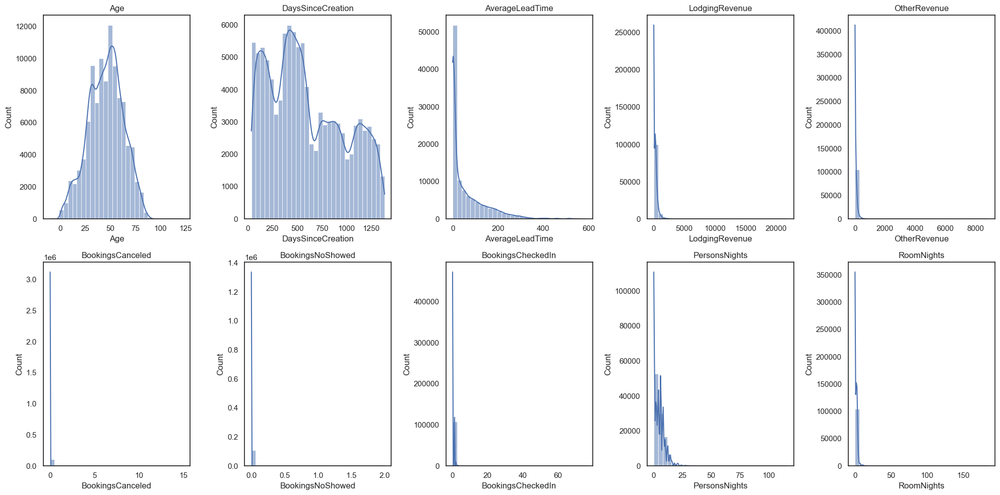

In [32]:
# Set style for better visualization
sns.set(style="white")

# Set the number of subplots
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot histograms for each numerical feature
for i, col in enumerate(numerical_features):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

# Adjust layout
plt.tight_layout()
plt.show()

__`Step 19.1`__ Creating a boxplot of the numerical features.

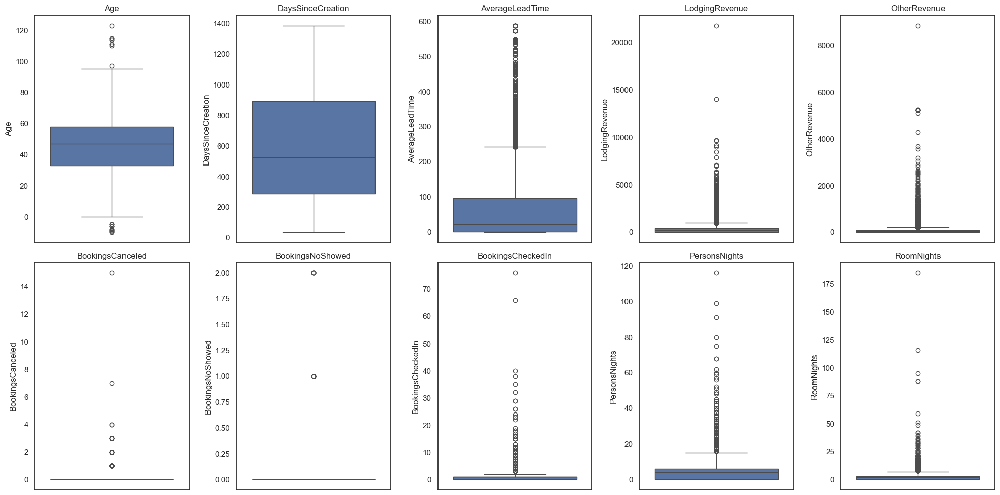

In [33]:
# Set style for better visualization
sns.set(style="white")

# Set the number of subplots
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))  # 2 rows, 5 columns

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot boxplots for each numerical feature
for i, col in enumerate(numerical_features):
    sns.boxplot(data=df, y=col, ax=axes[i])
    axes[i].set_title(col)

# Adjust layout
plt.tight_layout()
plt.show()

From the previous 2 plots some conclusions can be driven:

1. The vast majority of the numerical features have outliers (with exception of DaysSinceCreation).
2. From all the features presented in the dataset the ones that seem more useful to differentiate customers are `Age`, `DaysSinceCreation` and `AverageLeadTime`, this is because those features are the ones that present more dispersion between the values. The rest have are very skewed to the value 0 which make them very poor to differentiate groups. If we were to use all these numerical features at there native state we would probabaly end up with a clustering solution with 2 clusters, since there are very few variable that present non-extreme difference between the observations.
3. For the previous 2 reasons the urge for new variables is of major importance for our analysis.

__`Step 20`__ Create barplots of the categorical features.

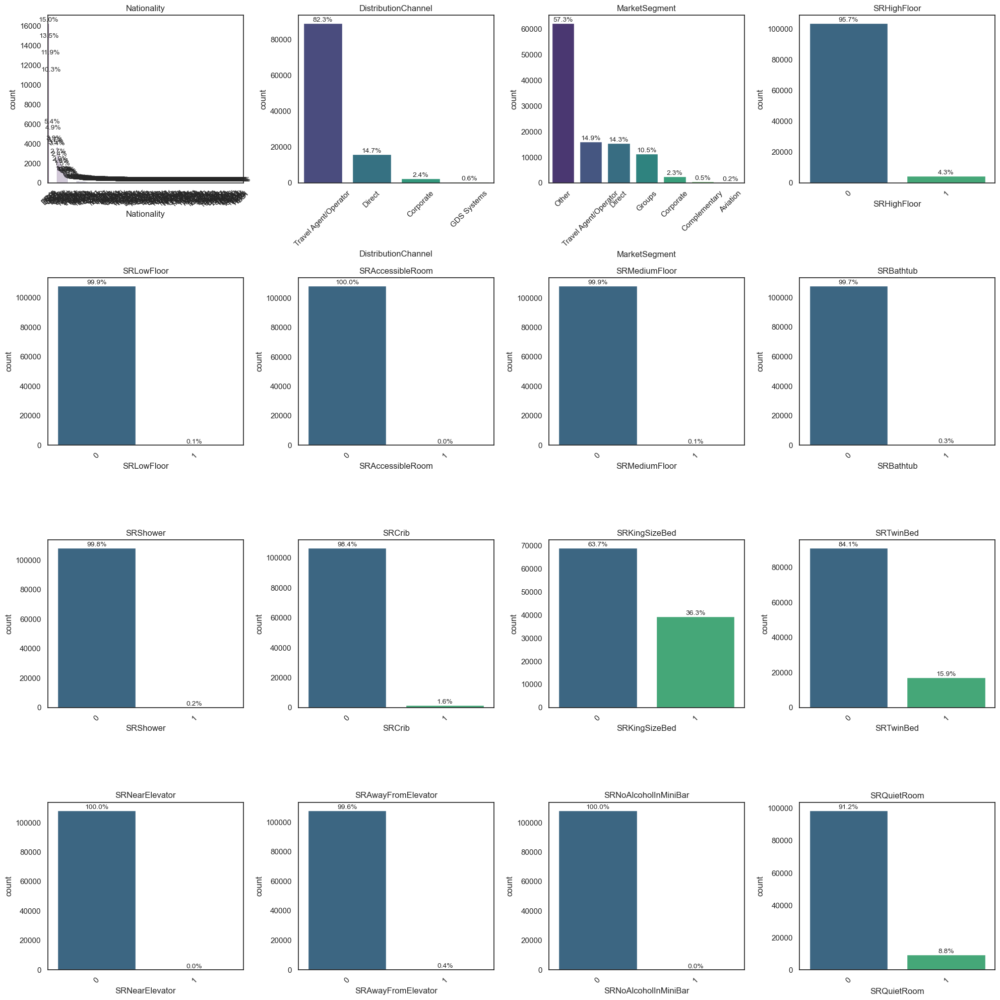

In [34]:
# Ignore all warnings
warnings.filterwarnings("ignore")

# Set style for better visualization
sns.set(style="white")

# Set the number of subplots
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(20, 20))  # 4 rows, 4 columns to fit 16 features

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot bar plots for each categorical feature
for i, col in enumerate(categorical_features):
    # Calculate the value counts and percentage
    counts = df[col].value_counts(normalize=True) * 100
    
    # Sort the categories by percentage (descending)
    sorted_counts = counts.sort_values(ascending=False)
    
    # Create a countplot with the sorted categories
    sns.countplot(data=df, x=col, ax=axes[i], order=sorted_counts.index, palette="viridis")
    
    # Set the title of the subplot
    axes[i].set_title(col)
    
    # Rotate x labels if necessary for better readability
    axes[i].tick_params(axis='x', rotation=45)
    
    # Display percentages on top of each bar
    for p in axes[i].patches:
        height = p.get_height()
        percentage = (height / df[col].shape[0]) * 100
        axes[i].text(p.get_x() + p.get_width() / 2, height + 1, f'{percentage:.1f}%', 
                     ha='center', va='bottom', fontsize=10)

# Remove unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Adjust layout
plt.tight_layout()
plt.show()

__`Step 21`__ Plotting a tree map to check what are the type of requests customers ask the most, for those customers that ask for special requests.

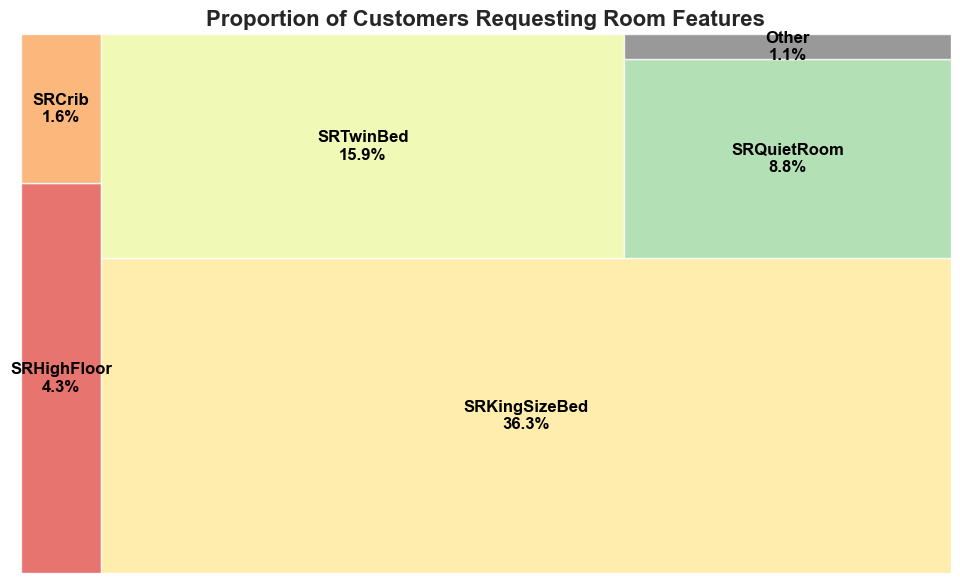

In [35]:
# Calculate the proportion of customers requesting each feature
feature_proportions = df[sr_features].mean()

# Threshold for "Other" category
threshold = 0.01

# Separate small and large categories
small_features = feature_proportions[feature_proportions < threshold]
large_features = feature_proportions[feature_proportions >= threshold]

# Sum small features into "Other"
if not small_features.empty:
    large_features["Other"] = small_features.sum()

# Use a color palette
colors = sns.color_palette("Spectral", len(large_features))  # Diverse colors
colors[-1] = (0.5, 0.5, 0.5)  # Set "Other" as gray for distinction

# Create Treemap
plt.figure(figsize=(12, 7))
squarify.plot(
    sizes=large_features.values, 
    label=[f"{feat}\n{round(val * 100, 1)}%" for feat, val in large_features.items()], 
    alpha=0.8, 
    color=colors,
    text_kwargs={'fontsize': 12, 'color': 'black', 'weight': 'bold'}
)

# Formatting
plt.title("Proportion of Customers Requesting Room Features", fontsize=16, fontweight='bold')
plt.axis("off")  # Hide axes
plt.show()

From the analysis of the bar plots and the tree map we can see that:

1. Nationality has a very huge cardinality, so for effects of profilling it will be needed to be dealt with so we can get useful insights from it's bar plots.
2. There is a huge imbalance between the categories in `Distribution Channel` and `Market Segments` which make them not so good to differentiate in the profiling stage.
3. The majority of people don't ask for special requests, the ones that do normally ask for them, ask for a KingSizeBed, or a TwinBed or for a QuietRoom. Using a sum of all these special request features might not be the brightess of the ideas, since it's distribution would be pulled hugely to 0.

__`Step 22`__ Check the previous customer segmentation done and the results they provide.

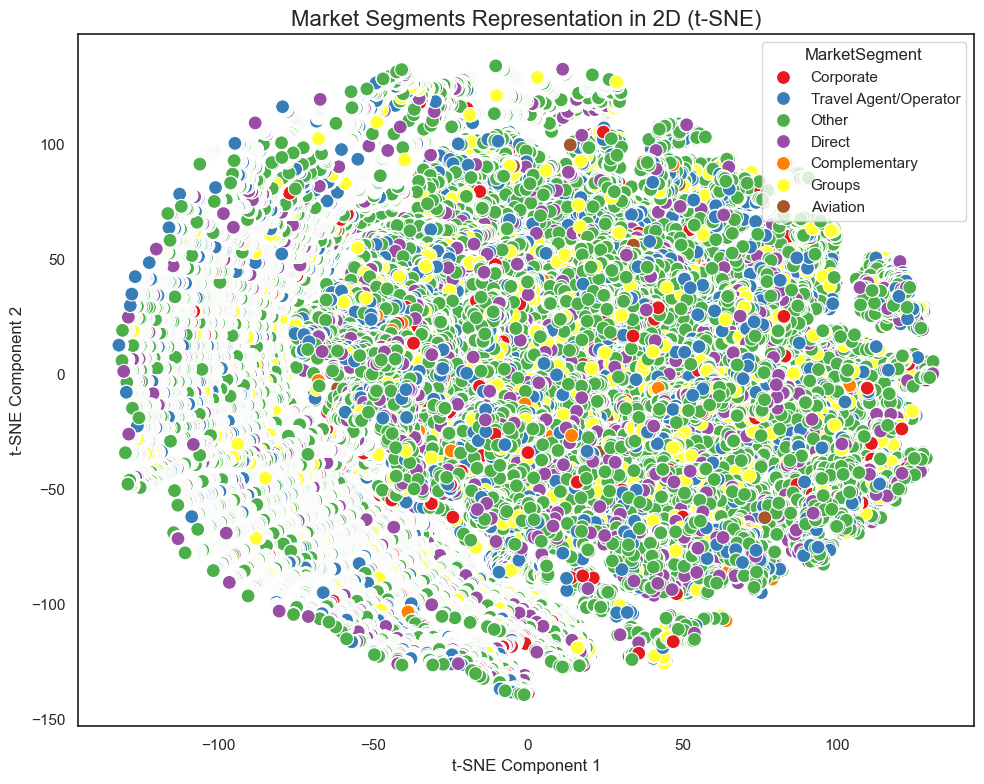

In [ ]:
data = df.copy()

# Step 1: Impute missing values in the 'Age' column with the mean
imputer = SimpleImputer(strategy='mean')  # Impute missing values with the mean
data['Age'] = imputer.fit_transform(data[['Age']])  # Apply imputation to the 'Age' column

# Step 2: Extract the numerical features from the DataFrame
numerical_data = data[numerical_features]

# Step 3: Standardize the numerical features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(numerical_data)  # Scale the data

# Step 4: Perform t-SNE to reduce to 2D
tsne = TSNE(n_components=2, random_state=42)
tsne_components = tsne.fit_transform(scaled_features)

# Step 5: Create a DataFrame with t-SNE components and MarketSegments
tsne_data = pd.DataFrame(tsne_components, columns=['TSNE1', 'TSNE2'])
tsne_data['MarketSegment'] = data['MarketSegment']

# Step 6: Create the 2D scatter plot, color by MarketSegments
plt.figure(figsize=(10, 8))
sns.scatterplot(data=tsne_data, x='TSNE1', y='TSNE2', hue='MarketSegment', palette='Set1', s=100, marker='o')

# Set the plot title and labels
plt.title('Market Segments Representation in 2D (t-SNE)', fontsize=16)
plt.xlabel('t-SNE Component 1', fontsize=12)
plt.ylabel('t-SNE Component 2', fontsize=12)

# Display the plot
plt.tight_layout()
plt.show()

We can clearly see that the market segmentation previously done is not an ideal one, because we can't observe a clear separation between the groups of features, which make the segmentation not very effective, since it seems it only separates people based on the type of industry they work not based on there purchasing behaviour.

## 2.8. Additional Features Exploration

__`Step 23`__ Create a new feature named `PersonRoom` that is the division between `PersonNights` and `RoomNights`.

In [36]:
df['PersonRoom'] = df['PersonsNights'] / df['RoomNights']

__`Step 23.1`__ Creating an histogram and boxplot of this new feature alongside with features `PersonsNight` and `RoomNight`

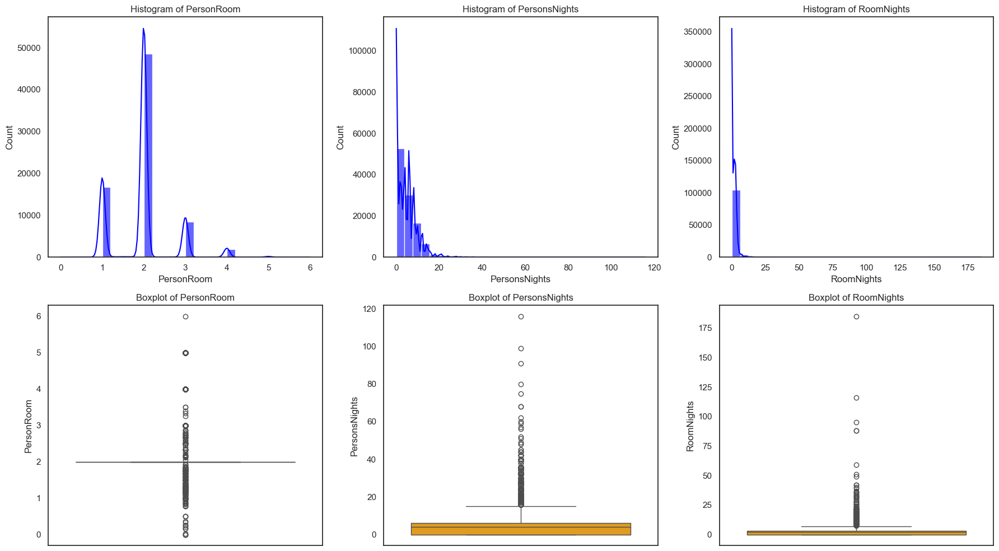

In [37]:
# Set Seaborn style to white
sns.set_style("white")

# Create a figure with 2 rows and 3 columns (3 histograms + 3 boxplots)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))

# Feature list for iteration
features = ['PersonRoom', 'PersonsNights', 'RoomNights']

# Plot histograms (first row)
for i, feature in enumerate(features):
    sns.histplot(df[feature], bins=30, kde=True, ax=axes[0, i], color="blue", alpha=0.6)
    axes[0, i].set_title(f'Histogram of {feature}')

# Plot boxplots (second row)
for i, feature in enumerate(features):
    sns.boxplot(y=df[feature], ax=axes[1, i], color="orange")
    axes[1, i].set_title(f'Boxplot of {feature}')

# Adjust layout
plt.tight_layout()
plt.show()

From the boxplot this new created feature seems to have a lot of outliers, which makes it not so ideal to use for clustering.

__`Step 24`__ Transforming the binary special request features into useful discrete variables.

In [38]:
df['FloorRequests'] = df[['SRHighFloor', 'SRLowFloor', 'SRMediumFloor']].sum(axis=1)
df['RoomFeatureRequests'] = df[['SRBathtub', 'SRShower', 'SRKingSizeBed', 'SRTwinBed']].sum(axis=1)
df['AccessibilityRequests'] = df[['SRAccessibleRoom', 'SRCrib']].sum(axis=1)
df['ElevatorRequests'] = df[['SRNearElevator', 'SRAwayFromElevator']].sum(axis=1)
df['NoiseRequests'] = df['SRQuietRoom']

__`Step 24.1`__ Creating boxplots and histograms of the new created features in the dataset.

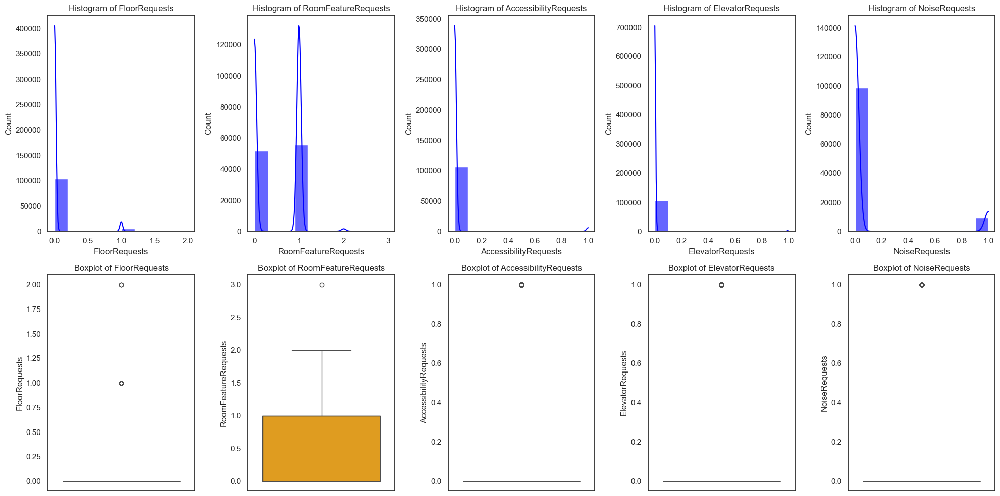

In [39]:
# Set Seaborn style
sns.set_style("white")

# Define the features
special_request_features = ['FloorRequests', 'RoomFeatureRequests', 'AccessibilityRequests', 
                            'ElevatorRequests', 'NoiseRequests']

# Create a figure with 2 rows and 5 columns (5 histograms + 5 boxplots)
fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(20, 10))

# Plot histograms (first row)
for i, feature in enumerate(special_request_features):
    sns.histplot(df[feature], bins=10, kde=True, ax=axes[0, i], color="blue", alpha=0.6)
    axes[0, i].set_title(f'Histogram of {feature}')

# Plot boxplots (second row)
for i, feature in enumerate(special_request_features):
    sns.boxplot(y=df[feature], ax=axes[1, i], color="orange")
    axes[1, i].set_title(f'Boxplot of {feature}')

# Adjust layout
plt.tight_layout()
plt.show()


We can clearly see that from all this new created features the one that seems to be the best to be used is `RoomFeatureRequests`. This is because it is the only that presents some sort of distribution and that is not so pushed into the value 0. This happens because as we saw in the univariate feature exploration, there are very few customers that ask for special requests.

__`Step 25`__ Creating a feature that is the sum of the special requests.

In [40]:
df['TotalSpecialRequests'] = df[['SRHighFloor', 'SRLowFloor', 'SRMediumFloor', 'SRBathtub', 'SRShower', 'SRKingSizeBed', 'SRTwinBed', 
                                 'SRAccessibleRoom', 'SRCrib', 'SRNearElevator', 'SRAwayFromElevator', 'SRQuietRoom', 'SRNoAlcoholInMiniBar'
                                 ]].sum(axis=1)

__`Step 25.1`__ Ploting the boxplot and histogram of the fature `TotalSpecialRequests`.

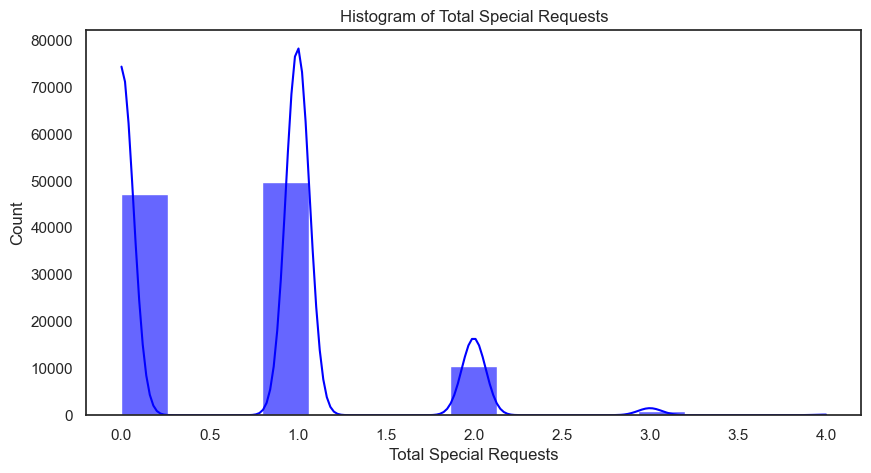

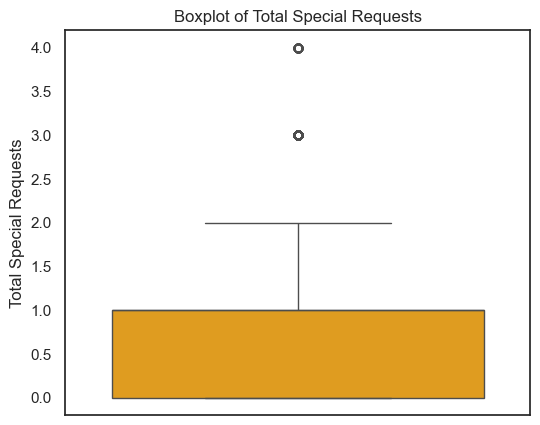

In [41]:
# Set Seaborn style
sns.set_style("white")

# Create figure for Histogram
plt.figure(figsize=(10, 5))
sns.histplot(df['TotalSpecialRequests'], bins=15, kde=True, color="blue", alpha=0.6)
plt.title('Histogram of Total Special Requests')
plt.xlabel('Total Special Requests')
plt.ylabel('Count')
plt.show()

# Create figure for Boxplot
plt.figure(figsize=(6, 5))
sns.boxplot(y=df['TotalSpecialRequests'], color="orange")
plt.title('Boxplot of Total Special Requests')
plt.ylabel('Total Special Requests')
plt.show()

The feature `TotalSpecialRequests`resembles the same distribution of `RoomFeatureRequests` (previously identified as one of our best features for clustering from the created features about special requests). So, for the reasoning that this new feature stores the information from all the special requests it will be preferable to be used then `RoomFeatureRequests`.

__`Step 26`__ Creating several other features to see if there distributions are better than the individual ones.

In [42]:
# Total Revenue
df["TotalRevenue"] = df["LodgingRevenue"] + df["OtherRevenue"]

# Booking Frequency
df["RevenuePerStay"] = df["TotalRevenue"] / df["BookingsCheckedIn"]

# Nights per Booking
df["PersonsNightsPerBooking"] = df["PersonsNights"] / df["BookingsCheckedIn"]

# Revenue per Day Since Creation
df["RevenuePerDaySinceCreation"] = df["TotalRevenue"] / df["DaysSinceCreation"]

__`Step 26.1`__ Check the distribution of this 5 new created features.

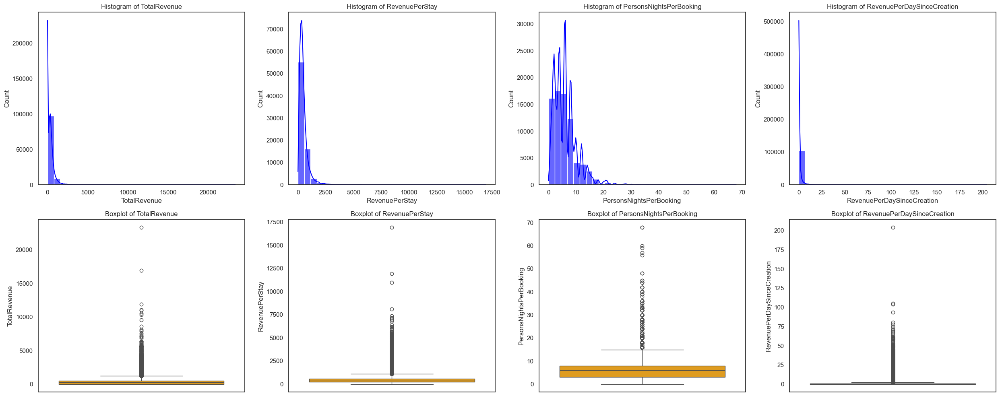

In [43]:
# Define the new features
new_features = ["TotalRevenue", "RevenuePerStay", "PersonsNightsPerBooking", "RevenuePerDaySinceCreation"]

# Set Seaborn style
sns.set_style("white")

# Create a figure with 2 rows and 5 columns (5 histograms + 5 boxplots)
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(25, 10))

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot histograms (first row)
for i, feature in enumerate(new_features):
    sns.histplot(df[feature], bins=30, kde=True, ax=axes[i], color="blue", alpha=0.6)
    axes[i].set_title(f'Histogram of {feature}')

# Plot boxplots (second row)
for i, feature in enumerate(new_features):
    sns.boxplot(y=df[feature], ax=axes[i + len(new_features)], color="orange")
    axes[i + len(new_features)].set_title(f'Boxplot of {feature}')

# Adjust layout
plt.tight_layout()
plt.show()

From this 4 new features, we see the usefulness of considering them instead of the individual components, for the following reasons:

1. They mix the information of several features in a single one, aiding avoiding the curse of dimensionality.
2. They minimize the impact of using a lot of features, whose distribution is very pushed to 0.

Nonetheless, `TotalRevenue` will not be used for clustering because we already can capture revenue related information from the features `RevenuePerStay` and `RevenuePerDaySinceCreation`.

__`Step 27`__ Create a dictionary that store the average income per each country.

In [44]:
avg_income = {"ABW": 2510, "AFG": 3840, "AGO": 2456, "AIA": 2500, "ALB": 7944, "AND": 50148, "ARE": 27107, "ARG": 12888, "ARM": 6780, 
              "ASM": 13000, "ATA": 0, "ATF": 0, "ATG": 17500, "AUS": 63156, "AUT": 55032, "AZE": 6660, "BDI": 960, "BEL": 54576, "BEN": 1560, 
              "BES": 670, "BFA": 1200, "BGD": 2880, "BGR": 14280, "BHR": 25000, "BHS": 27500, "BIH": 8280, "BLR": 7788, "BLZ": 7800, 
              "BMU": 130296, "BOL": 3624, "BRA": 9276, "BRB": 25640, "BRN": 39500, "BTN": 4500, "BWA": 9300, "CAF": 1080, "CAN": 54036, 
              "CHE": 83332, "CHL": 15804, "CHN": 13392, "CIV": 2000, "CMR": 1692, "COD": 900, "COG": 1800, "COK": 18000, "COL": 6816, 
              "COM": 1700, "CPV": 5700, "CYM": 46000, "CRI": 14256, "CUB": 3000, "CYP": 32964, "CZE": 27372, "DEU": 54804, "DJI": 5700, 
              "DMA": 12700, "DNK": 73344, "DOM": 10800, "DZA": 4200, "ECU": 6588, "EGY": 3840, "ERI": 1500, "ESP": 51336, "EST": 27624, 
              "ETH": 1800, "FIN": 53232, "FLK": 32000, "FRA": 45180, "FRO": 62000, "FSM": 6500, 'FJI': 9400, "GAB": 11500, "GBR": 57617, 
              "GEO": 6708, "GHA": 3240, "GIB": 35000, "GIN": 1200, "GMB": 2300, "GNB": 820, "GNQ": 12600, "GRC": 22596, "GRD": 9600, 
              "GRL": 19296, "GTM": 6500, "GUF": 28000, "GUY": 8700, "HKG": 55176, "HND": 7200, "HRV": 20592, "HTI": 1764, "HUN": 19668, 
              "IDN": 4812, "IND": 2544, "IOT": 0, "IRL": 78972, "IRN": 4656, "IRQ": 7200, "ISL": 80400, "ISR": 54648, "ITA": 37920, 
              "JAM": 9500, "JEY": 57000, "JOR": 9200, "JPN": 39348, "KAZ": 10728, "KEN": 3000, "KGZ": 1764, "KHM": 2388, "KIR": 5500, 
              "KNA": 15000, "KOR": 35496, "KWT": 45000, "LAO": 3100, "LBN": 10200, "LBR": 1800, "LBY": 12500, "LCA": 10400, "LIE": 10019, 
              "LKA": 4000, "LSO": 4200, "LTU": 25080, "LUX": 83976, "LVA": 22632, "MAC": 45960, "MAR": 7200, "MCO": 190000, "MDA": 6204, 
              "MDG": 1700, "MDV": 10500, "MEX": 11976, "MHL": 7600, "MKD": 9500, "MLI": 1400, "MLT": 34752, "MMR": 2300, "MNE": 11592, 
              "MNG": 7200, "MOZ": 2400, "MRT": 4200, "MUS": 11200, "MWI": 1500, "MYS": 11712, "NAM": 9200, "NCL": 38000, "NER": 1400, 
              "NGA": 1884, "NIC": 6500, "NLD": 62544, "NOR": 102912, "NPL": 1428, "NRU": 10800, "NZL": 48216, "OMN": 28000, "PAK": 1464, 
              "PAN": 15450, "PCN": 0, "PER": 7370, "PHL": 3900, "PLW": 8400, "PNG": 2600, "POL": 41050, "PRI": 21000, "PRK": 33871, 
              "PRT": 37500, "PRY": 5800, "PYF": 22000, "QAT": 61000, "ROU": 15860, "RUS": 26146, "RWA": 900, "SAU": 23500, "SDN": 1300, 
              "SEN": 1700, "SGP": 60720, "SJM": 62000, "SLV": 8100, "SMR": 48000, "SOM": 900, "SPM": 37000, "SRB": 10800, "SSD": 1100, 
              "STP": 2200, "SUR": 7200, "SVK": 21000, "SVN": 28200, "SWE": 57996, "SLE": 2100, "SYC": 17100, "SWZ": 4500,"SYR": 1400, 
              "TCD": 1300, "TGO": 1100, "THA": 7300, "TJK": 1400, "TKM": 7800, "TMP": 1500, "TON": 5500, "TTO": 15500, "TUN": 3800, 
              "TUR": 22048, "TWN": 33700, "TZA": 1120, "UGA": 1000, "UKR": 4000, "UMI": 0, "URY": 17700, "USA": 80115, "UZB": 2200, 
              "VEN": 1568, "VCT": 8500, "VIR": 39000, "VNM": 4100, "WLF": 15600, "WSM": 4100, "YEM": 1100, "ZAF": 21663, "ZWE": 2200}

This dictionary data was taken from the following reference:

Salary Explorer | Salary and Cost of Living Comparison. (n.d.). Retrieved 6 March 2025, from https://www.salaryexplorer.com/

Then it was converted into a dictionary with the aid of GenAI (ChatGPT) to be inputed in the dataset as an aditional feature. We decided to get this additional feature, because in this way we can use the information in Nationality using the average salary of the country it comes from as an indicator to wether the customers comes from a country in which people have on average an higher purchasing power.

__`Step 27.1`__ Creating the new feature called `AvgIncome`. 

In [45]:
# Mapping the AvgIncome based on Nationality
df["AvgIncome"] = df["Nationality"].map(avg_income)

__`Step 27.2`__ Create the histogram and boxplot of this new created feature.

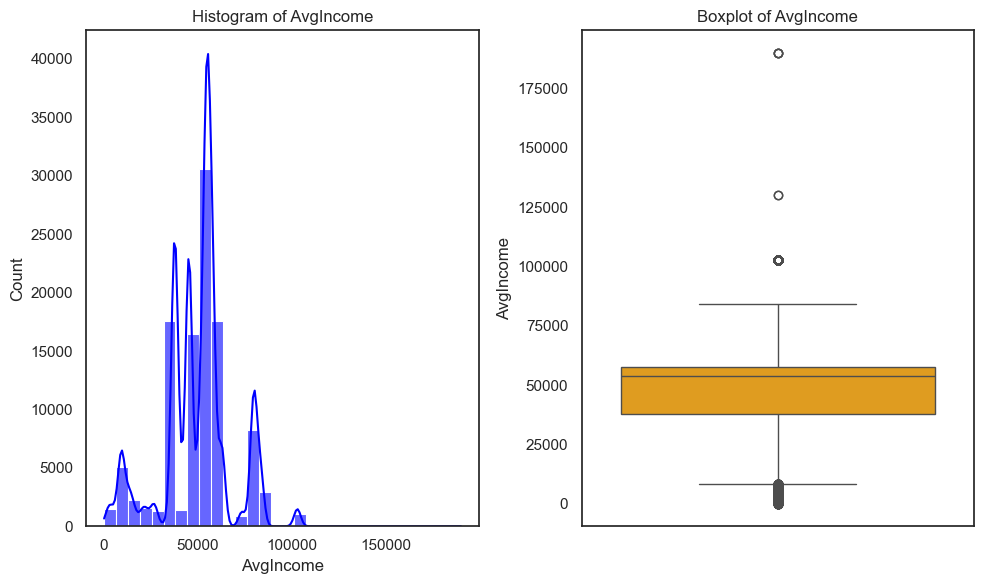

In [46]:
# Set Seaborn style
sns.set_style("white")

# Create a figure with 2 rows and 1 column (1 histogram + 1 boxplot)
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 6))

# Plot histogram (first row)
sns.histplot(df["AvgIncome"], bins=30, kde=True, ax=axes[0], color="blue", alpha=0.6)
axes[0].set_title("Histogram of AvgIncome")

# Plot boxplot (second row)
sns.boxplot(y=df["AvgIncome"], ax=axes[1], color="orange")
axes[1].set_title("Boxplot of AvgIncome")

# Adjust layout
plt.tight_layout()
plt.show()


The distribution of this fearure seems way better than the general distributions of the native variables of the dataset, which make it a plausible candidate for a good aditional feature. Nonetheless, it still presents some outliers that can be to some extent problematic.

__`Step 28`__ Add the new created features into the list of numerical features.

In [47]:
numerical_features.extend(['PersonRoom','FloorRequests','RoomFeatureRequests', 'AccessibilityRequests', 'ElevatorRequests', 'NoiseRequests', 
                           'TotalSpecialRequests', 'TotalRevenue', 'RevenuePerStay', 'PersonsNightsPerBooking', 'RevenuePerDaySinceCreation', 
                           'AvgIncome'])

## 2.9. Multivariate Analysis

### 2.9.1. Pairwise relationship between numerical features

__`Step 29`__ Create a correlation matrix of the numerical features to understand feature redundancy.

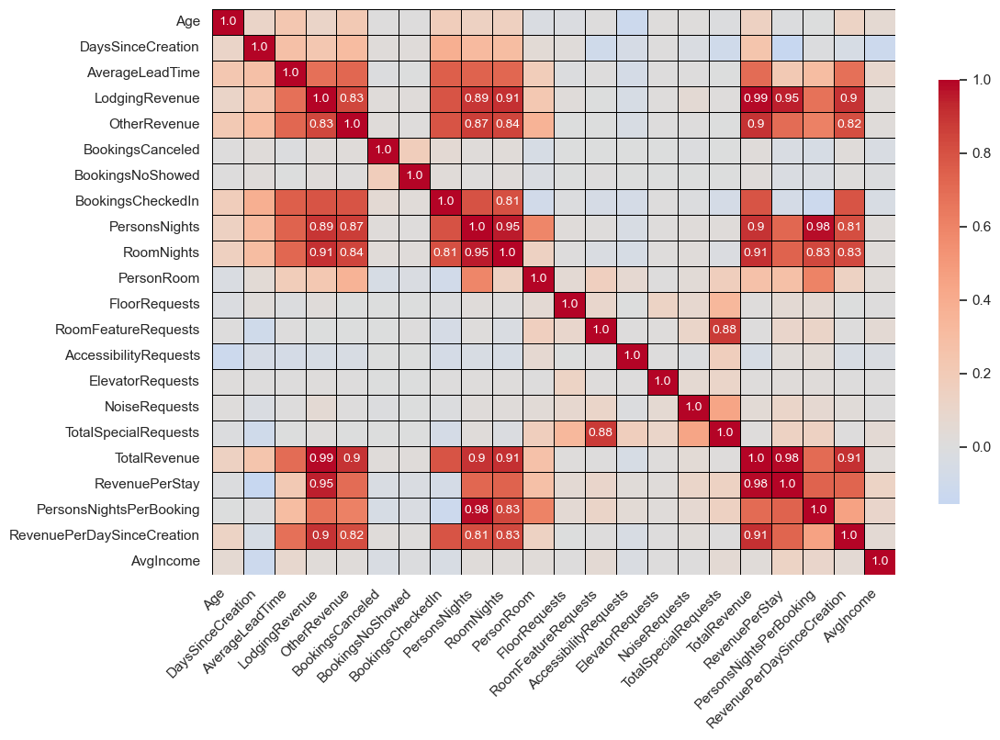

In [48]:
def cor_heatmap1(cor, threshold=0.8):
    # Create a mask for correlations that are above the threshold or below the negative threshold
    annot = np.where((cor >= threshold) | (cor <= -threshold), cor.round(2), "")  # Only show values >= threshold or <= -threshold
    
    # Set up the plot
    plt.figure(figsize=(12, 8))
    
    # Create the heatmap
    sns.heatmap(data=cor, annot=annot, cmap="coolwarm", center=0, linewidths=0.5, linecolor='black',
                cbar_kws={'shrink': 0.75}, annot_kws={"size": 10}, fmt='')  # Empty format for mixed strings and floats
    
    # Rotate x and y axis labels for readability
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)  # Ensuring y-axis labels are horizontal
    
    # Show the plot
    plt.show()


# Compute the Spearman correlation matrix using the correctly combined features list
corr_matrix = df[numerical_features].corr(method='spearman')

# Call the function to create the heatmap with the threshold applied
cor_heatmap1(corr_matrix, threshold=0.8)

We can see from this graph the following high correlations:

- PersonsNights is highly correlated with LodgingRevenue and OtherRevenue.
- RoomNIghts is highly correlated with LodgingRevenue, OtherRevenue, BookingsCheckedIn and PersonsNights.
- TotalSpecialRequests is highly correlated with RoomFeatureRequests (which was expected since there distribution is very similar).
- RevenueperStay is highly correlated with LodgingRevenue and TotalRevenue.
- PersonsNightsPerBooking is highly correlated with PersonsNights and RoomsNights.
- RevenuePerDaySinceCreation is highly correlated with LodgingRevenue, OtherRevenue, PersonsNights and RoomsNights.

These high correlation will need to be accounted for in the process of feature selection, because including them would heavily bias our results as we would be including redundant features into the analysis.

__`Step 30`__ Create a pairwise plot of numerical features to understand possible multivariate outliers.

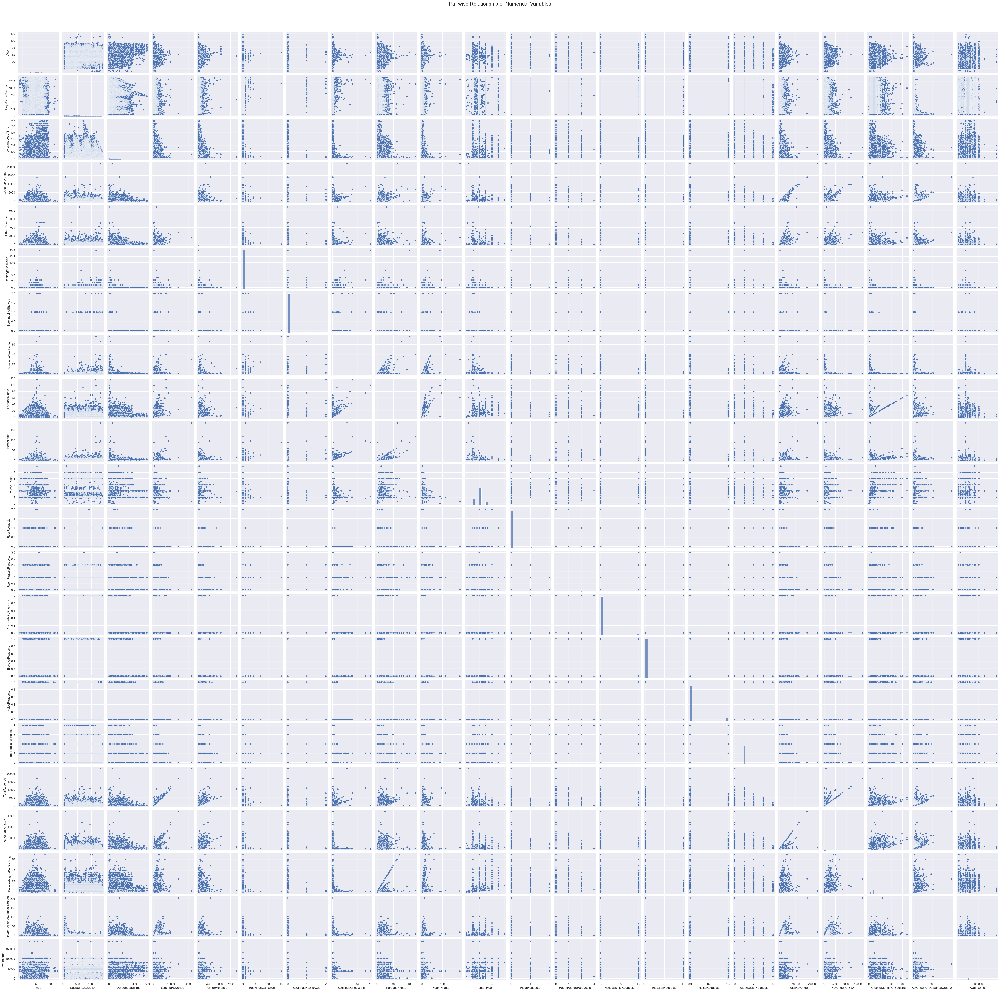

In [ ]:
# Pairwise Relationship of Numerical Variables
sns.set()

# Setting pairplot
sns.pairplot(df[numerical_features], diag_kind="hist")

# Layout
plt.subplots_adjust(top=0.95)
plt.suptitle("Pairwise Relationship of Numerical Variables", fontsize=20)

# if the eda directory is not present then create it first
if not os.path.exists('figures'):
    os.makedirs('figures')
    
plt.savefig(os.path.join('figures', 'pairwise_numeric_scatterplots.png'), dpi=200)
plt.show()

From this plot we can see that we have some multivariate outliers that might influence the performance of our clustering algorithms.

### 2.9.2. Comparing categorical features

__`Step 31`__ Ploting the categorical features against each other in order to identify possible relationships amongst them.

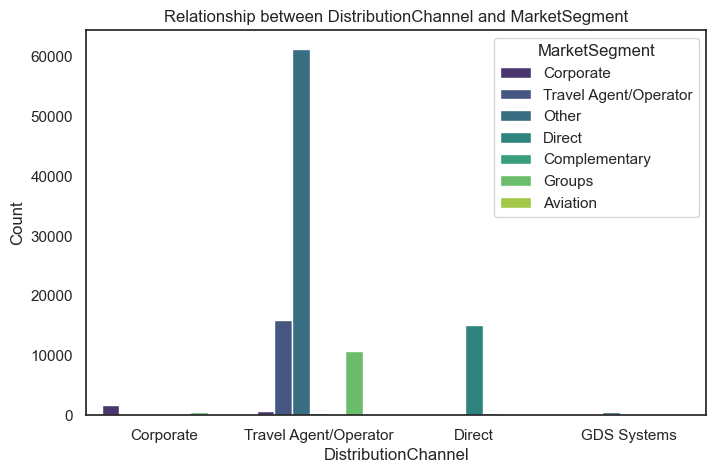

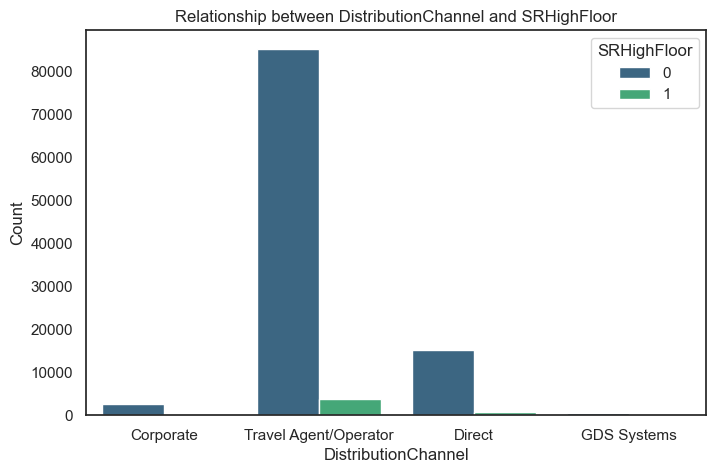

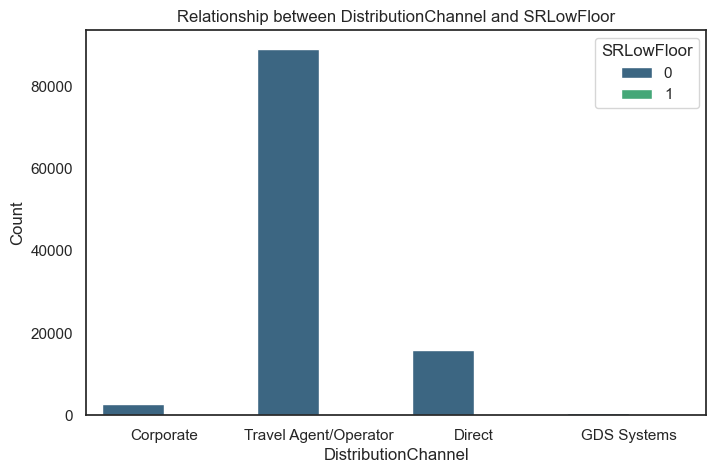

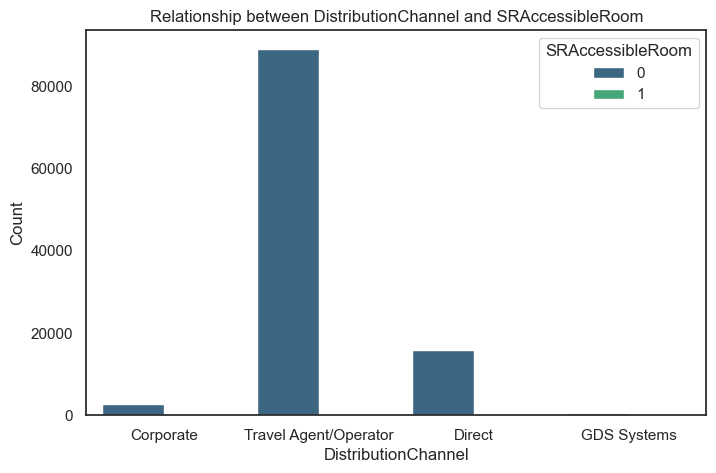

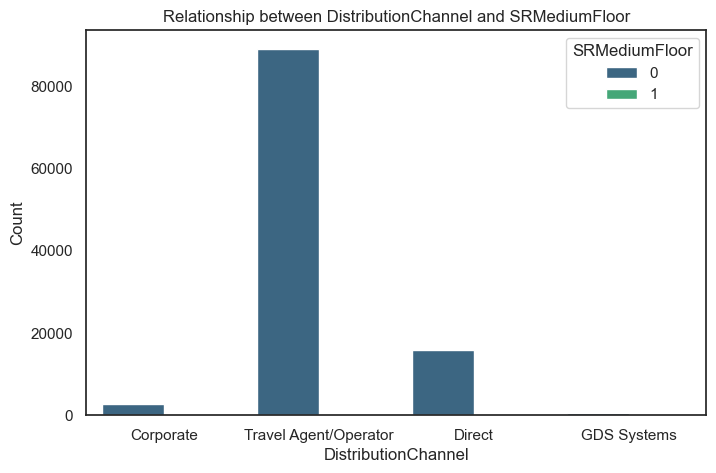

...

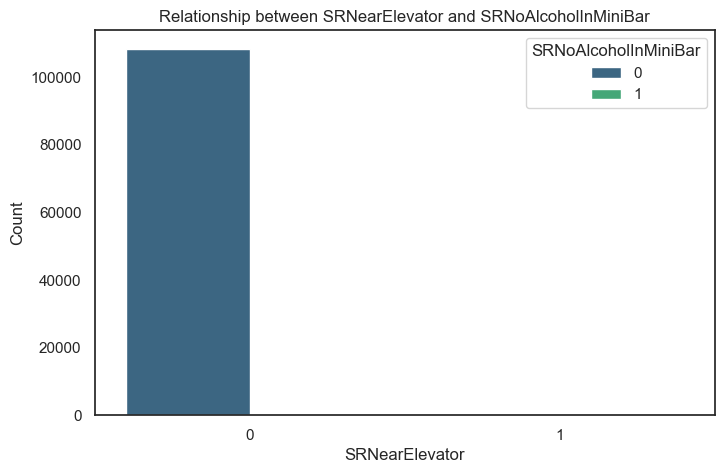

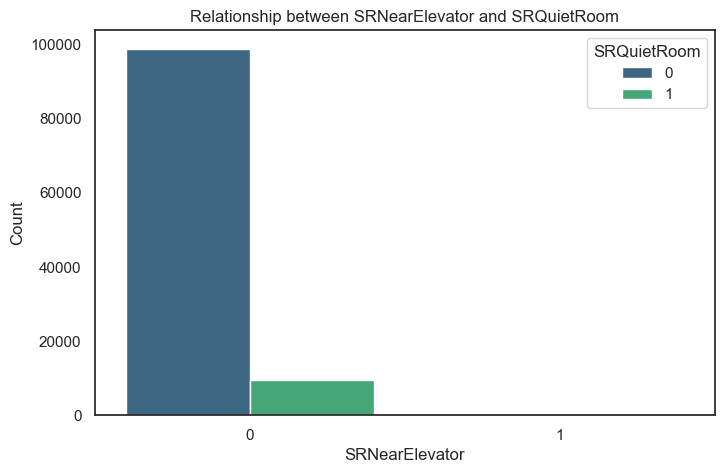

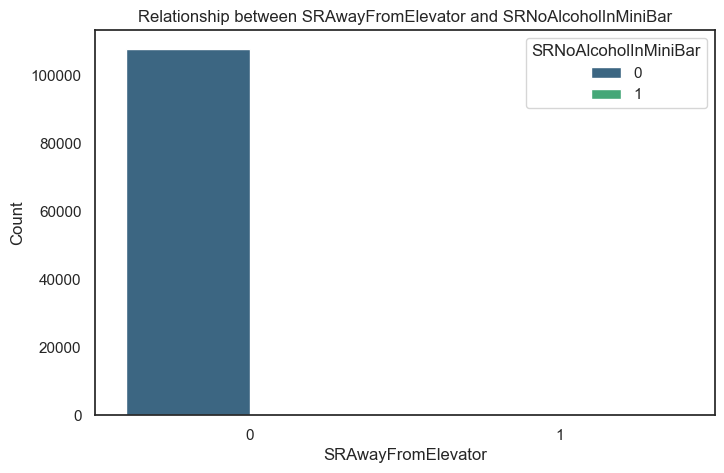

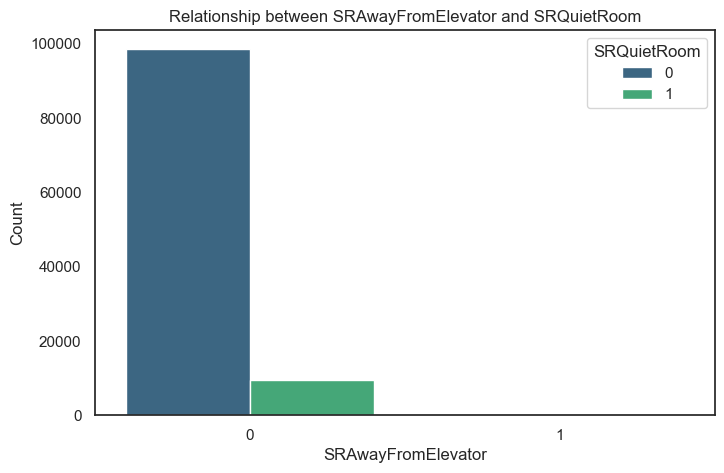

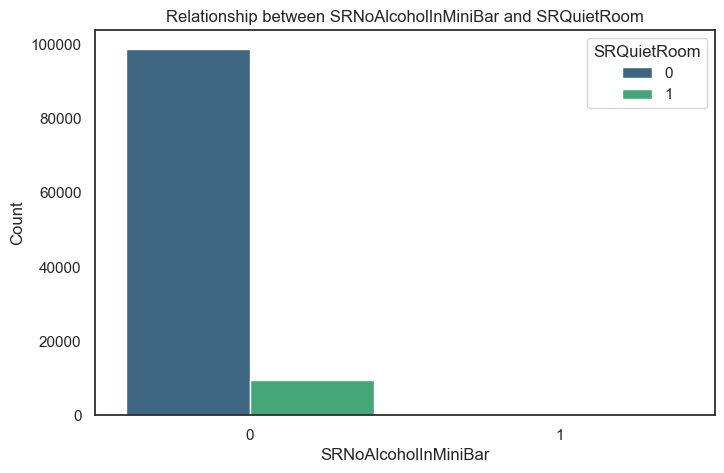

In [49]:
categorical_features1 = [feature for feature in categorical_features if feature != "Nationality"]

# Generate all possible pairs of categorical features
feature_pairs = list(itertools.combinations(categorical_features1, 2))

# Plot countplots for each pair
for cat1, cat2 in feature_pairs:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=cat1, hue=cat2, palette='viridis')
    plt.title(f"Relationship between {cat1} and {cat2}")
    plt.xlabel(cat1)
    plt.ylabel("Count")
    plt.legend(title=cat2)
    plt.show()

No major relevant relationship between variables was identified, the most distintive insight from these graphics is that the market segment 'Other' as more individuals that asked for a King sized bed that those that did not.

### 2.9.3. Comparing categorical vs Numerical features

__`Step 32`__ Checking the relationship between Lodging Revenue and the type of special requests that are made.

In [50]:
# Compare LodgingRevenue for customers who requested these features vs. those who didn't
for feature in sr_features:
    print(f"\nAverage Lodging Revenue for {feature}:")
    print(df.groupby(feature)["LodgingRevenue"].mean())


Average Lodging Revenue for SRHighFloor:
SRHighFloor
0    284.174827
1    314.397432
Name: LodgingRevenue, dtype: float64

Average Lodging Revenue for SRLowFloor:
SRLowFloor
0    285.417844
1    324.074929
Name: LodgingRevenue, dtype: float64

Average Lodging Revenue for SRAccessibleRoom:
SRAccessibleRoom
0    285.463516
1    304.650833
Name: LodgingRevenue, dtype: float64

Average Lodging Revenue for SRMediumFloor:
SRMediumFloor
0    285.433666
1    332.827564
Name: LodgingRevenue, dtype: float64

Average Lodging Revenue for SRBathtub:
SRBathtub
0    285.440373
1    294.023064
Name: LodgingRevenue, dtype: float64

Average Lodging Revenue for SRShower:
SRShower
0    285.310527
1    380.543296
Name: LodgingRevenue, dtype: float64

Average Lodging Revenue for SRCrib:
SRCrib
0    286.574977
1    218.757254
Name: LodgingRevenue, dtype: float64

Average Lodging Revenue for SRKingSizeBed:
SRKingSizeBed
0    281.500181
1    292.415540
Name: LodgingRevenue, dtype: float64

Average Lodging Rev

Analysing the lodging revenue based on special request made, the following insights are drawn:

- People that ask for a MediumFloor on average spend much more, on there room, that those who don't and spend more than those that ask for a SmallFloor or HighFloor;
- People that ask for an AccessibleRoom spend more, on there room, than those that don't ask for it;
- Poeple that ask for a Shower spend more, on there room, than those that ask for a BathTub;
- People that ask for a Crib spend less, on there room, than those that don't;
- People that ask for a King size bed spend more, on there room, than those than ask for a Twin bed;
- People that ask for a room away from the elevator spend more, on there room, than those that ask for a room near the elevator;
- People that ask for no alcohol in the mini bar spend less money than those money, on there room, from those that don't ask for no alcohol in the mini bar.
- People that ask for a quiet room spend more in there room that those that do not ask for it.

__`Step 32.1`__ Checking the average age of customers based on the special requests they make.

In [51]:
# Compare LodgingRevenue for customers who requested these features vs. those who didn't
for feature in sr_features:
    print(f"\nAverage Lodging Revenue for {feature}:")
    print(df.groupby(feature)["Age"].mean())


Average Lodging Revenue for SRHighFloor:
SRHighFloor
0    45.667419
1    43.745193
Name: Age, dtype: float64

Average Lodging Revenue for SRLowFloor:
SRLowFloor
0    45.576846
1    51.246377
Name: Age, dtype: float64

Average Lodging Revenue for SRAccessibleRoom:
SRAccessibleRoom
0    45.583134
1    51.227273
Name: Age, dtype: float64

Average Lodging Revenue for SRMediumFloor:
SRMediumFloor
0    45.583124
1    47.253333
Name: Age, dtype: float64

Average Lodging Revenue for SRBathtub:
SRBathtub
0    45.606941
1    38.622419
Name: Age, dtype: float64

Average Lodging Revenue for SRShower:
SRShower
0    45.578426
1    49.044944
Name: Age, dtype: float64

Average Lodging Revenue for SRCrib:
SRCrib
0    45.891991
1    27.244354
Name: Age, dtype: float64

Average Lodging Revenue for SRKingSizeBed:
SRKingSizeBed
0    45.931583
1    44.985767
Name: Age, dtype: float64

Average Lodging Revenue for SRTwinBed:
SRTwinBed
0    45.185829
1    47.674842
Name: Age, dtype: float64

Average Lodging R

Analysing the age of customers based on special request made, the following insights are drawn:

- People that ask for a LowFloor room are older, on average, that those who don't and spend more than those that ask for a SmallFloor or HighFloor;
- People that ask for an AccessibleRoom are older, on average, than those that don't ask for it;
- Poeple that ask for a Shower are older, on average, than those that ask for a BathTub;
- People that ask for a Crib are younger, on average, than those that don't;
- People that ask for a King size bed are younger, on average, than those than ask for a Twin bed;
- People that ask for a room away from the elevator are younger, on average, than those that ask for a room near the elevator;
- People that ask for no alcohol in the mini bar are younger, on average, than those that don't ask for no alcohol in the mini bar.
- People that ask for a quiet room seem to be sightly older than those that don't, but the different is very minimal.

__`Step 33`__ Checking the customers that use the most common distribution channel and that have an Average Lead Time of 0 ("walk-ins").

In [52]:
# Filter the dataset for the specific condition
zero_lead_travel_agent = df[(df['DistributionChannel'] == 'Travel Agent/Operator') & (df['AverageLeadTime'] == 0)]

# Count how many customers meet this condition
count_zero_lead_travel_agent = zero_lead_travel_agent.shape[0]

print(f"Number of customers with 'Travel Agent/Operator' as Distribution Channel and Average Lead Time = 0: {count_zero_lead_travel_agent}")

Number of customers with 'Travel Agent/Operator' as Distribution Channel and Average Lead Time = 0: 28164


__`Step 33.1`__ Checking the different distribution of average lead time per distribution channel.

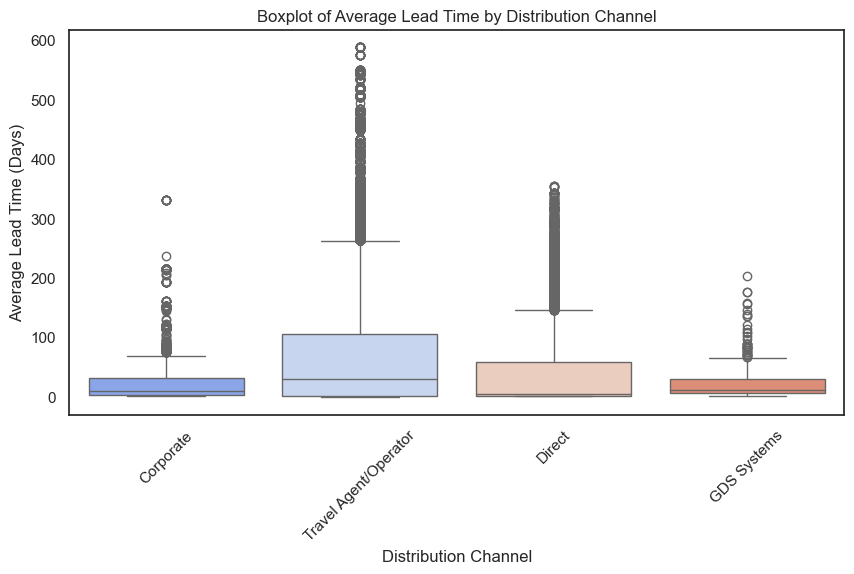

In [53]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['DistributionChannel'], y=df['AverageLeadTime'], palette='coolwarm')
plt.xlabel('Distribution Channel')
plt.ylabel('Average Lead Time (Days)')
plt.title('Boxplot of Average Lead Time by Distribution Channel')
plt.xticks(rotation=45)
plt.show()

From the 2 previous steps we can conclude:

1. There are 28164 "walk-ins" that used a Travel Agent/Operator as there distribution channel.
2. People that use the Travel Agent/Operator distribution channel seem to plan there travels earlier as they do have an higher median `AverageLeadTime`. People that used a direct distribution channel present a lower median value in `AverageLeadTime`.

# 3. Data Preparation

## 3.1. Treating Incoherences

__`Step 34`__ Removing all the customers that represent leads in the dataset.

In [54]:
df_filtered = df[~((df["RoomNights"] == 0) & (df["PersonsNights"] == 0) & (df["LodgingRevenue"] == 0) & (df["BookingsCanceled"] < 1) & 
                   (df["BookingsCheckedIn"] < 1) & (df["BookingsNoShowed"] < 1))]

len(df_filtered)

76033

__`Step 35`__ Changing the Nationality code of Timor-Leste to be coherent with current ISO alpha-3 country code.

In [55]:
df_filtered = df_filtered.replace({'Nationality': {'TMP': 'TLS'}})

df_filtered[df['Nationality'] == 'TLS']

,Nationality,Age,DaysSinceCreation,NameHash,DocIDHash,AverageLeadTime,LodgingRevenue,OtherRevenue,BookingsCanceled,BookingsNoShowed,...,RoomFeatureRequests,AccessibilityRequests,ElevatorRequests,NoiseRequests,TotalSpecialRequests,TotalRevenue,RevenuePerStay,PersonsNightsPerBooking,RevenuePerDaySinceCreation,AvgIncome
ID,,,,,,,,,,,,,,,,,,,,,


__`Step 36`__ Removing the following incoherences in the data: <br>

1. People that did more than one booking and did not pay any lodging revenue;
2. People that did not make any check-in and spend money on lodging revenue and other revenue;
3. People that are younger than 16 (for compliance with GDPR) and that are older than 110 (since developing a plan for these people that are outliers would be a very short-term investment, that could prove not profitable).
4. Remove people that have negative average lead time.

In [56]:
df_filtered = df_filtered[~(
    ((df_filtered['BookingsCheckedIn'] > 1) & (df_filtered['LodgingRevenue'] == 0)) |
    ((df_filtered['BookingsCheckedIn'] == 0) & (df_filtered['LodgingRevenue'] != 0) & (df_filtered['LodgingRevenue'] != 0)) |
    ((df_filtered["Age"] < 16) | (df_filtered['Age'] >= 110)) |
    (df_filtered['AverageLeadTime'] < 0))]

len(df_filtered)

75306

__`Step 37`__ Remove poeple that did more check-ins than nights spent in the hotel.

In [57]:
df_filtered = df_filtered[~((df_filtered["BookingsCheckedIn"] > df_filtered["RoomNights"]) | 
                            (df_filtered["BookingsCheckedIn"] > df_filtered["PersonsNights"]))]

## 3.2. Outliers

__`Step 38`__ Creating boxplots of the features that will be used for clustering.

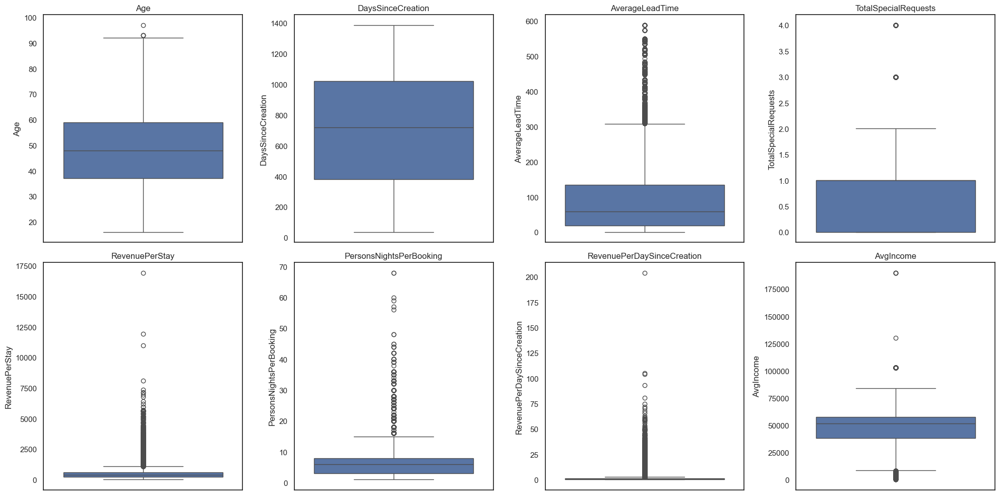

In [58]:
# Creating a list of the features to use for clustering
clustering_features = ["Age", "DaysSinceCreation", "AverageLeadTime", "TotalSpecialRequests", "RevenuePerStay", "PersonsNightsPerBooking", 
                       "RevenuePerDaySinceCreation", "AvgIncome"]

# Set style for better visualization
sns.set(style="white")

# Set the number of subplots
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))  # 2 rows, 4 columns

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot boxplots for each numerical feature
for i, col in enumerate(clustering_features):
    sns.boxplot(data=df_filtered, y=col, ax=axes[i])
    axes[i].set_title(col)

# Adjust layout
plt.tight_layout()
plt.show()

__`Step 38.1`__ Remove the most extreme outliers.

In [59]:
df_filtered = df_filtered[df_filtered['RoomFeatureRequests'] < 2.5]
df_filtered = df_filtered[df_filtered['PersonsNightsPerBooking'] < 50]
df_filtered = df_filtered[df_filtered['RevenuePerStay'] < 10000]
df_filtered = df_filtered[df_filtered['AvgIncome'] < 175000]
df_filtered = df_filtered[df_filtered['RevenuePerDaySinceCreation'] < 200]

len(df_filtered)

75281

Notice that only some features are plotted (the ones that will be used for clustering), because it results from several testing of K-Means with differrent features and the one that gave us the better results are the ones presented there. Those several tests are not presented in this notebook to make sure that it is readable and not a gigantic Jupyter Notebook.

Moreover we decided to only take out the most extreme outliers, since as our objective is customer segmentation we still want to classify outliers as they represent in same variables our VIP customer (the ones that spend the most). This process (including incoherence) treatment lead to the removal of around 1% of the dataset.

## 3.3. Feature Engeneering

__`Step 39`__ Create a list with the features that will be used normalized using Johnson transformation.

In [60]:
normalization_features = ["RevenuePerStay", "RevenuePerDaySinceCreation"]

__`Step 39.1`__ Apply the Johnson transformation to these features.

In [61]:
# Ensures all columns have positive values
for column in normalization_features:
    if (df_filtered[column] <= 0).any():
        df_filtered[column] += abs(df_filtered[column].min()) + 1e-6

# Apply the Johnson Yeost transformation
pt = PowerTransformer(method='yeo-johnson', standardize=True) 
johnson_transformed = pt.fit_transform(df_filtered[normalization_features])

# Convert back to a dataframe
johnson_df_filtered = pd.DataFrame(johnson_transformed, columns=normalization_features, index=df_filtered.index)

df_filtered[normalization_features] = johnson_df_filtered[normalization_features]
df_filtered[normalization_features]

,RevenuePerStay,RevenuePerDaySinceCreation
ID,,
1,-0.907459,0.249287
2,-0.210065,-1.025773
4,-0.342855,-1.105703
6,-0.548588,-1.223258
8,0.666524,-0.440208
...,...,...
111725,1.453268,2.104393
111727,-0.880977,1.750824
111728,-1.459737,1.471167


__`Step 39.2`__ Check the distribution of the features after applying the power transformation (using histograms).

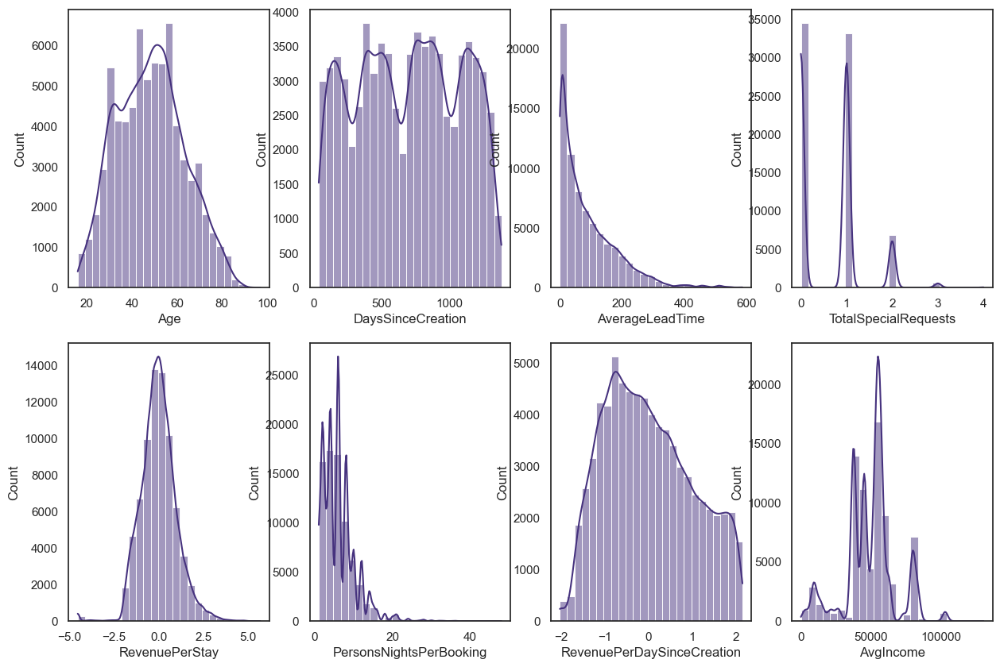

In [62]:
sns.set(style="white", palette="viridis")

fig, axes = plt.subplots(2, 4, figsize=(15, 10))

for ax, feat in zip(axes.flatten(), clustering_features): # Notice the zip() function and flatten() method
    sns.histplot(df_filtered[feat],bins=25, kde=True , legend=False, ax = ax)

__`Step 39.3`__ Check the boxplot of the features to check the aplication of the Johnson transformation.

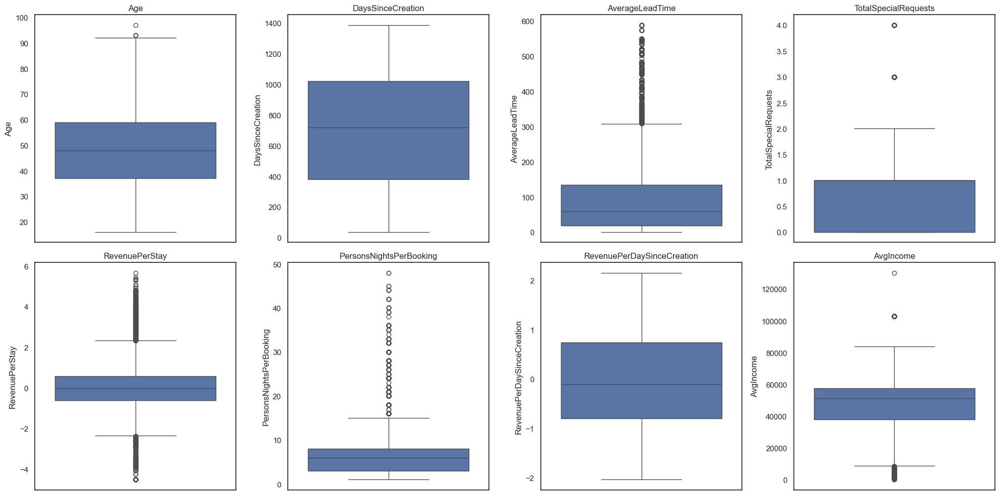

In [63]:
# Set style for better visualization
sns.set(style="white")

# Set the number of subplots
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))  # 2 rows, 5 columns

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot boxplots for each numerical feature
for i, col in enumerate(clustering_features):
    sns.boxplot(data=df_filtered, y=col, ax=axes[i])
    axes[i].set_title(col)

# Adjust layout
plt.tight_layout()
plt.show()

We performed the Johnson transformation in this 2 features because they were highly skewed and pushed towards 0. By doing this transformation we can improve the performance of our clustering algorithms as they usually perform better the closest features are from a normal distribution.

__`Step 40`__ Group the countries that are not among the top 20 nationalities into a category labeled 'Other'.

In [64]:
# Get the top 20 most frequent nationalities
top_20_nationalities = df_filtered["Nationality"].value_counts().head(20).index

# Replace all nationalities that are not in the top 20 with 'Other'
df_filtered["Nationality"] = df_filtered["Nationality"].apply(lambda x: x if x in top_20_nationalities else 'Other')

We decided to group these countries, so that the variable `Nationality` can be used more comprehensive way in the profilling of the final clustering solutions.

__`Step 41`__ Scaling the numeric features using the standard scaler.

In [65]:
# Initialize RobustScaler
scaler = StandardScaler()

# Fit and transform the numerical columns
df_filtered[numerical_features] = scaler.fit_transform(df_filtered[numerical_features])

We need to scale our features because the clustering algorithms that we are using in this customer segmentation initiative rely on distance calculations (euclidean distance). Therefore, not scaling our features would lead us to bias our analysis since variable with higher scales would be deemed as more important as they would lead to huger difference between different observation, and that is not the objective we want.

After testing MinMaxScaler, RobustScaler and StandardScaler the StandardScaler was the one that gave us the most consistent results in terms of cluster visualization and providing the cluster centroids that in our subjective analysis seemed more valuable to get actionable marketing recommendation for company H.

## 3.4. Missing values

__`Step 42`__ Making imputation in the age variable using the K-Nearest Neighbours with 20 neighbours.

In [66]:
# Store the index (ID) before imputation
df_index = df_filtered.index 

# Choose the features to be used for the imputation
features_for_imputation = numerical_features

# Select only numerical features for imputation
df_impute = df_filtered[features_for_imputation].copy()

# Initialize and apply KNN Imputer
imputer = KNNImputer(n_neighbors=20)
df_imputed_values = imputer.fit_transform(df_impute)

# Convert back to DataFrame and restore the index
df_impute = pd.DataFrame(df_imputed_values, columns=features_for_imputation, index=df_index)

# Restore the imputed "Age" values to the original dataframe
df.loc[df_index, "Age"] = df_impute["Age"]

We decided to use K-Nearest Neighbours, since it is a lazy predictor that does not require any training of the model, being capable of doing imputation n the data without having to be trained a priori, making our process of customer segmentation computationally faster.

__`Step 42.1`__ Checking if there are still missing values present in the dataset.

In [67]:
df_impute.isna().sum()

Age                           0
DaysSinceCreation             0
AverageLeadTime               0
LodgingRevenue                0
OtherRevenue                  0
BookingsCanceled              0
BookingsNoShowed              0
BookingsCheckedIn             0
PersonsNights                 0
RoomNights                    0
PersonRoom                    0
FloorRequests                 0
RoomFeatureRequests           0
AccessibilityRequests         0
ElevatorRequests              0
NoiseRequests                 0
TotalSpecialRequests          0
TotalRevenue                  0
RevenuePerStay                0
PersonsNightsPerBooking       0
RevenuePerDaySinceCreation    0
AvgIncome                     0
dtype: int64

__`Step 42.2`__ Add the categorical features into the dataset without missing values.

In [68]:
df_impute[categorical_features] = df_filtered[categorical_features].reset_index(drop=True)

## 3.5. Feature Selection

__`Step 43`__ Create a function to plot the heatmap of the numerical features correlation and display it.

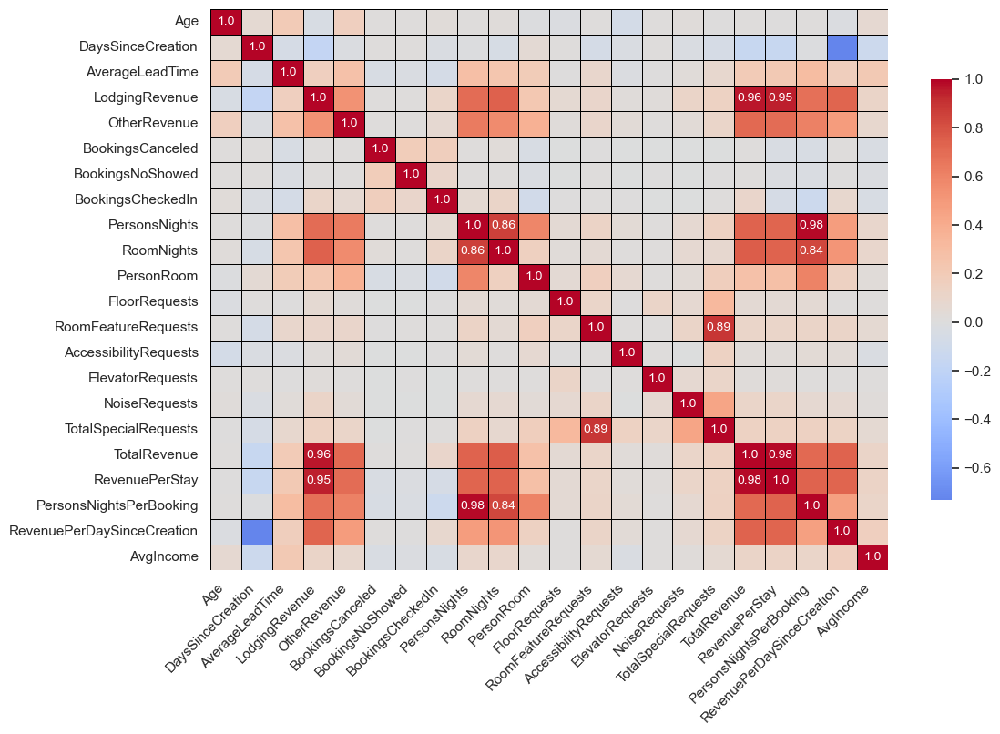

In [69]:
def cor_heatmap1(cor, threshold=0.8):
    # Create a mask for correlations that are above the threshold or below the negative threshold
    annot = np.where((cor >= threshold) | (cor <= -threshold), cor.round(2), "")  # Only show values >= threshold or <= -threshold
    
    # Set up the plot
    plt.figure(figsize=(12, 8))
    
    # Create the heatmap
    sns.heatmap(data=cor, annot=annot, cmap="coolwarm", center=0, linewidths=0.5, linecolor='black',
                cbar_kws={'shrink': 0.75}, annot_kws={"size": 10}, fmt='')  # Empty format for mixed strings and floats
    
    # Rotate x and y axis labels for readability
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)  # Ensuring y-axis labels are horizontal
    
    # Show the plot
    plt.show()

# Compute the Spearman correlation matrix using the correctly combined features list
corr_matrix = df_impute[numerical_features].corr(method='spearman')

# Call the function to create the heatmap with the threshold applied
cor_heatmap1(corr_matrix, threshold=0.8)

Based on this correlations and the insights from Data Understanding the following features will be removed:

- Total Revenue: Since it presents high correlations with LodgingRevenue and we have other variables that capture the revenue information like RevenueperStay;
- LodgingRevenue and OtherRevenue: Since there is already other variables that capture revenue effects and there because LodgingRevenue is highly correlated with RevenueperStay;
- PersonsNights and RoomNights: Because they are highly correlated with PersonsNightsPerBooking;
- RoomFeatureRequests: Because it is highly correlated with TotalSpecialRequests;
- FloorRequests, AccessibilityRequests, ElevatorRequests and NoiseRequests: Because we already have the aggragation TotalSpecialRequests that accounts for this features information;
- PersonRoom: Since in the exploration of the feature it's distribution is highly skewed and mostly composed of people with the value two, which makes difficult to differentiate between customers.

__`Step 43.1`__ Removing the features above mentioned from the dataset.

In [70]:
# List of features to be removed
features_to_remove = ["TotalRevenue", "LodgingRevenue", "OtherRevenue", "PersonsNights", "RoomNights", "RoomFeatureRequests", 
                      "FloorRequests", "AccessibilityRequests", "ElevatorRequests", "NoiseRequests", "PersonRoom"]

# Drop the specified columns from the DataFrame
df_impute = df_impute.drop(columns=features_to_remove)

__`Step 43.2`__ Removing those columns from the list of numerical features.

In [71]:
numerical_features = [col for col in numerical_features if col not in features_to_remove]

__`Step 43.3`__ Checking if there are high correlations between the features that will be used for clustering.

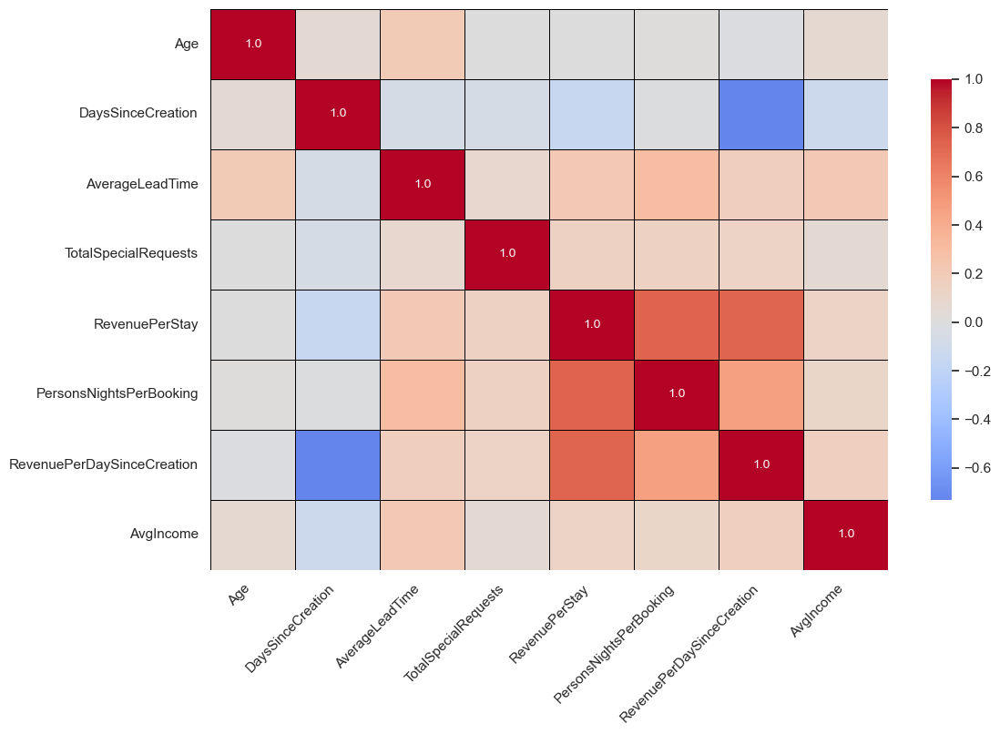

In [72]:
# Compute the Spearman correlation matrix using the correctly combined features list
corr_matrix = df_impute[clustering_features].corr(method='spearman')

# Call the function to create the heatmap with the threshold applied
cor_heatmap1(corr_matrix, threshold=0.8)

__`Step 43.4`__ Removing unecessary columns for the categorical features.

In [73]:
# Remove sr_features from categorical_features
categorical_features = [col for col in categorical_features if col not in sr_features]

# Drop sr_features from df_impute
df_impute = df_impute.drop(columns=sr_features)
df_impute.columns

Index(['Age', 'DaysSinceCreation', 'AverageLeadTime', 'BookingsCanceled',
       'BookingsNoShowed', 'BookingsCheckedIn', 'TotalSpecialRequests',
       'RevenuePerStay', 'PersonsNightsPerBooking',
       'RevenuePerDaySinceCreation', 'AvgIncome', 'Nationality',
       'DistributionChannel', 'MarketSegment'],
      dtype='object')

The sr binary features were removed as they were already accounted in our analysis by the employment of the feature `TotalSpecialRequests`, so analysing them in the profilling of the clusters would be time wasteful and they wouldn't provide major insights due to the huge imbalance in the majority of them. 

# 4. Modelling

## 4.1. Clustering

### 4.1.1. Testing solely K-Means

__`Step 44`__ Visualise the within-cluster sum of squares (WSS) for different cluster amounts of `perspective1` to determine the optimal amount of clusters for our data, also known as the elbow method

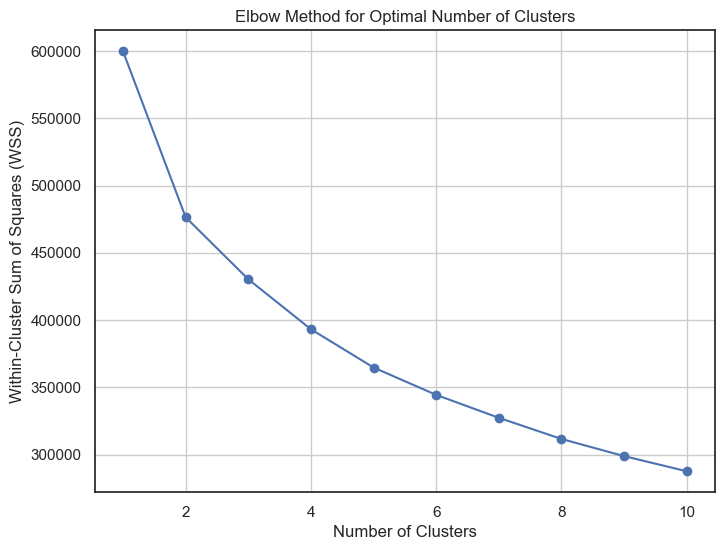

In [273]:
def plot_elbow_graph(data, max_clusters=10):
    # List to store the WSS (Within-Cluster Sum of Squares)
    wss = []
    
    # Iterate through a range of clusters
    for i in range(1, max_clusters+1):
        kmeans = KMeans(n_clusters=i, init='k-means++', n_init=15, random_state = 90)
        kmeans.fit(data)
        wss.append(kmeans.inertia_)
    
    # Plot the elbow graph
    plt.figure(figsize=(8, 6))
    plt.plot(range(1, max_clusters+1), wss, marker='o', linestyle='-', color='b')
    plt.title('Elbow Method for Optimal Number of Clusters')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Within-Cluster Sum of Squares (WSS)')
    plt.grid(True)
    plt.show()

plot_elbow_graph(df_impute[clustering_features])

- There is not a clear elbow in the image above but it seems closer to being 2, than any other number.

__`Step 45`__ Compute the average silhouette score to check what is the best number of clusters

For n_clusters = 2, the average silhouette_score is : 0.1910260125954231
For n_clusters = 3, the average silhouette_score is : 0.16488322099652064
For n_clusters = 4, the average silhouette_score is : 0.15975761673697533
For n_clusters = 5, the average silhouette_score is : 0.1431923554711559
For n_clusters = 6, the average silhouette_score is : 0.13421961455920392
For n_clusters = 7, the average silhouette_score is : 0.15021420257479964
For n_clusters = 8, the average silhouette_score is : 0.14811147300225647
For n_clusters = 9, the average silhouette_score is : 0.1396782540971528
For n_clusters = 10, the average silhouette_score is : 0.138464932349123


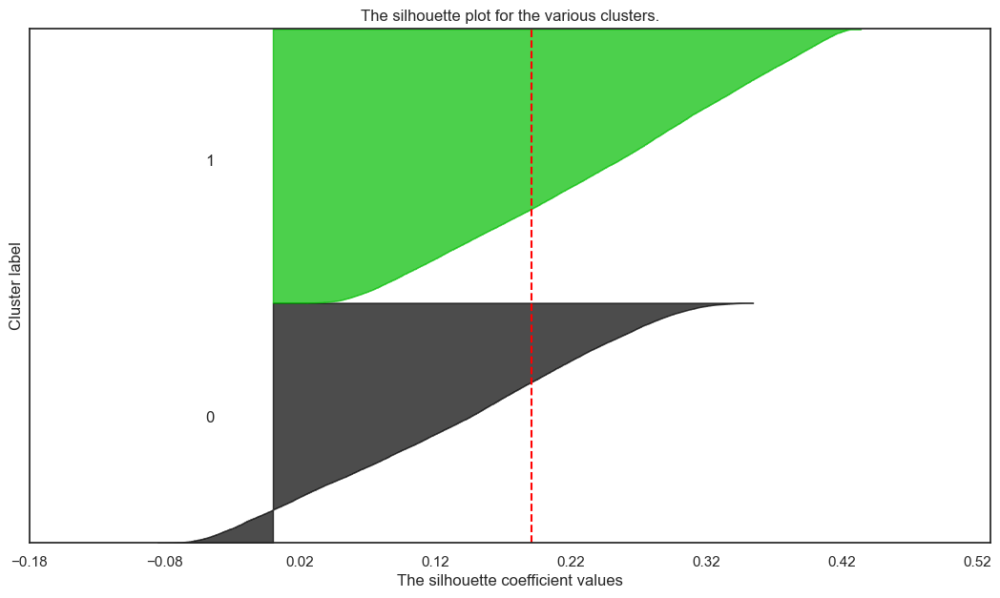

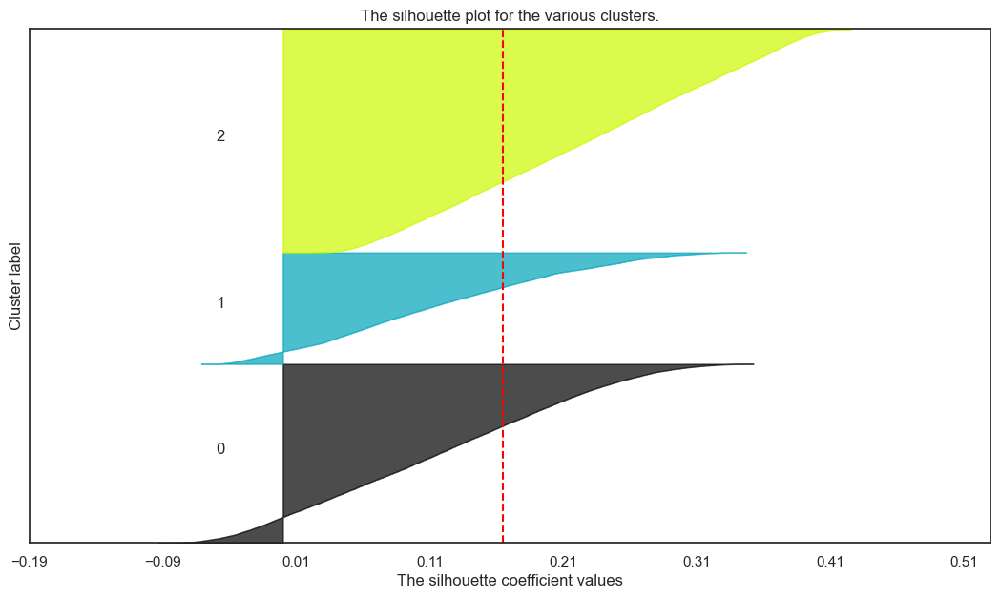

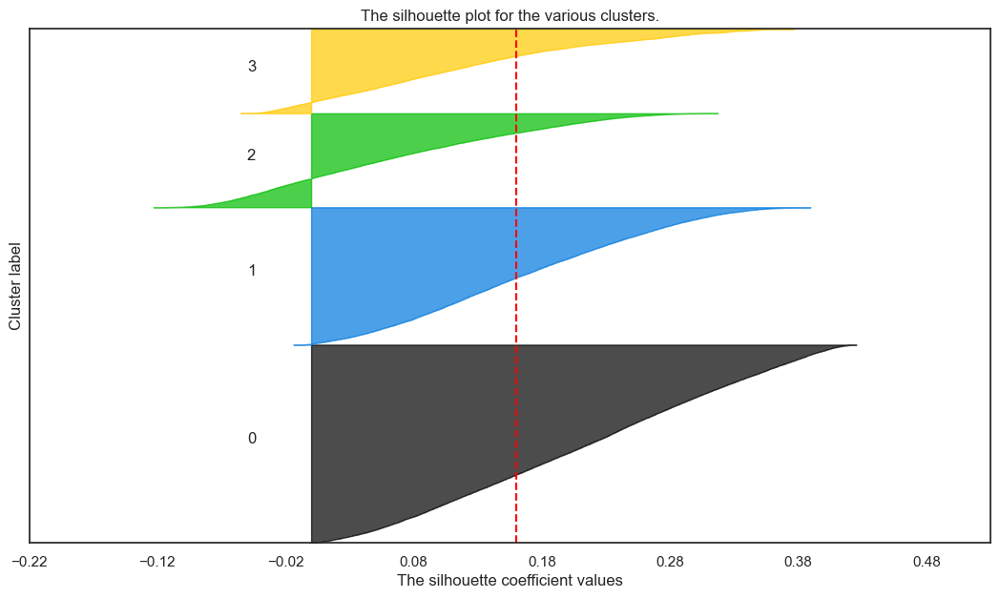

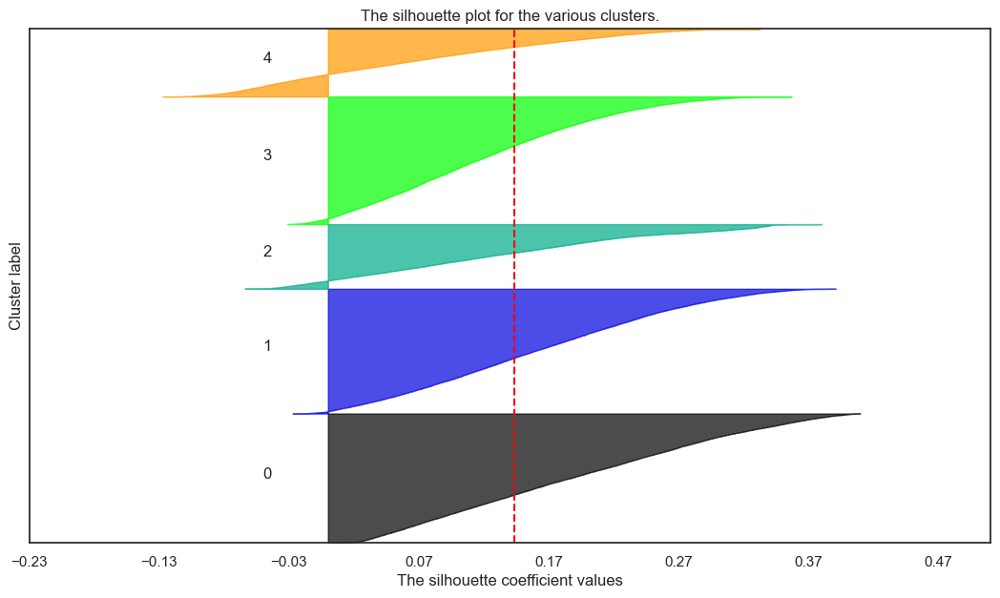

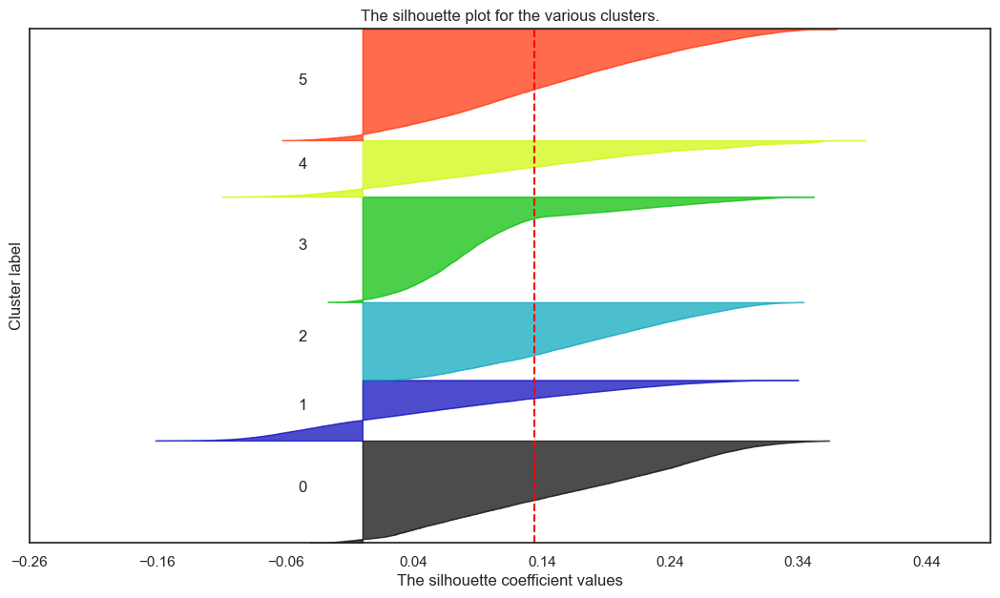

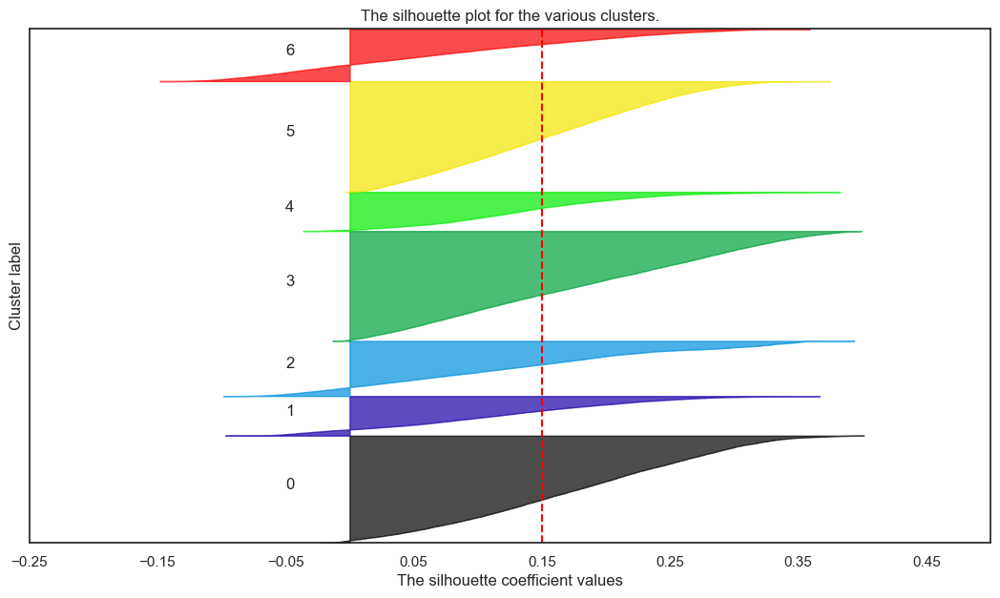

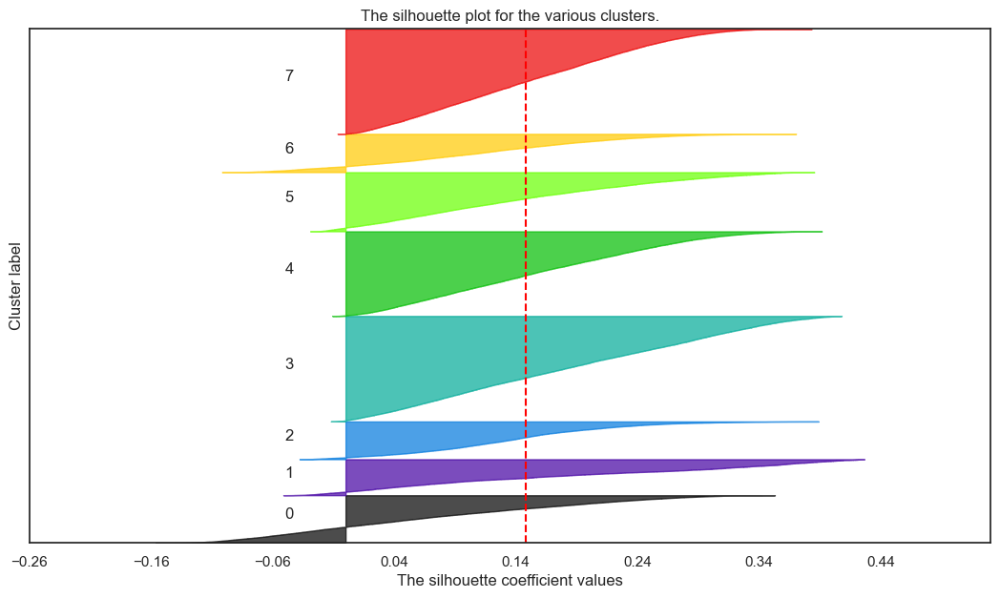

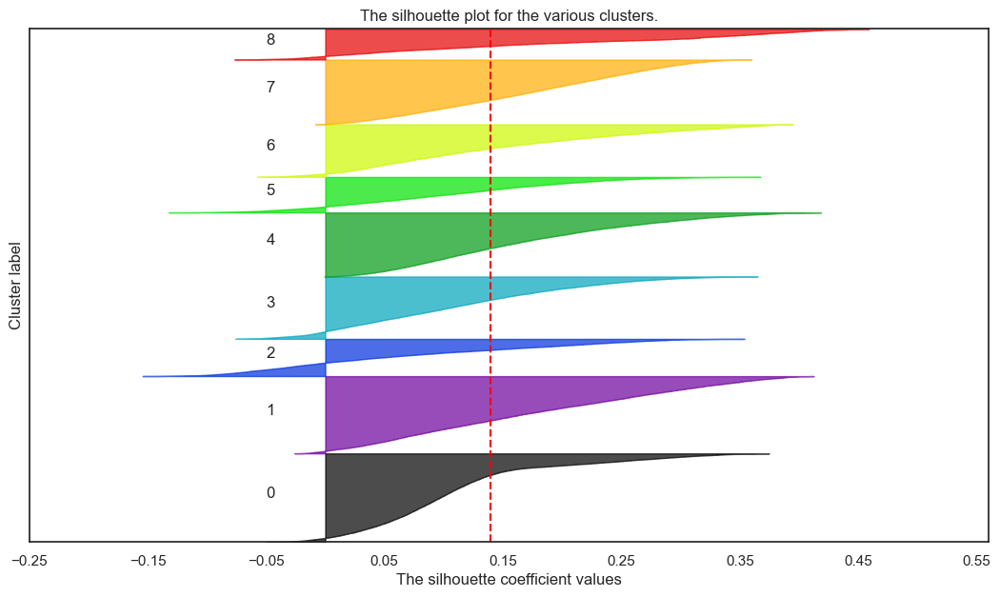

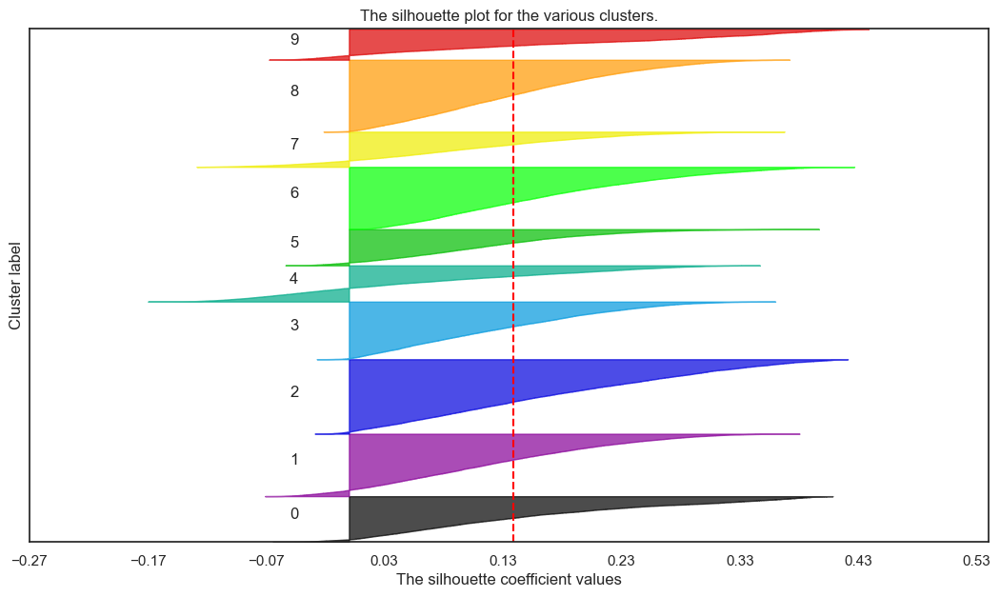

In [274]:
# Storing average silhouette metric
avg_silhouette = []
for nclus in range(1,11):
    # Skip nclus == 1
    if nclus == 1:
        continue
    
    # Create a figure
    fig = plt.figure(figsize=(13, 7))

    # Initialize the KMeans object with n_clusters value and a random generator
    # seed of 10 for reproducibility.
    kmclust = KMeans(n_clusters=nclus, init='k-means++', n_init=15, random_state=1)
    cluster_labels = kmclust.fit_predict(df_impute[clustering_features])

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed clusters
    silhouette_avg = silhouette_score(df_impute[clustering_features], cluster_labels)
    avg_silhouette.append(silhouette_avg)
    print(f"For n_clusters = {nclus}, the average silhouette_score is : {silhouette_avg}")

    # Compute the silhouette scores for each sample
    sample_silhouette_values = silhouette_samples(df_impute[clustering_features], cluster_labels)

    y_lower = 10
    for i in range(nclus):
        # Aggregate the silhouette scores for samples belonging to cluster i, and sort them
        ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
        ith_cluster_silhouette_values.sort()
        
        # Get y_upper to demarcate silhouette y range size
        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i
        
        # Filling the silhouette
        color = cm.nipy_spectral(float(i) / nclus)
        plt.fill_betweenx(np.arange(y_lower, y_upper),
                          0, ith_cluster_silhouette_values,
                          facecolor=color, edgecolor=color, alpha=0.7)

        # Label the silhouette plots with their cluster numbers at the middle
        plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))

        # Compute the new y_lower for next plot
        y_lower = y_upper + 10  # 10 for the 0 samples

    plt.title("The silhouette plot for the various clusters.")
    plt.xlabel("The silhouette coefficient values")
    plt.ylabel("Cluster label")

    # The vertical line for average silhouette score of all the values
    plt.axvline(x=silhouette_avg, color="red", linestyle="--")
    
    # The silhouette coefficient can range from -1, 1
    xmin, xmax = np.round(sample_silhouette_values.min() -0.1, 2), np.round(sample_silhouette_values.max() + 0.1, 2)
    plt.xlim([xmin, xmax])
    
    # The (nclus+1)*10 is for inserting blank space between silhouette
    # plots of individual clusters, to demarcate them clearly.
    plt.ylim([0, len(df_impute[clustering_features]) + (nclus + 1) * 10])

    plt.yticks([])  # Clear the yaxis labels / ticks
    plt.xticks(np.arange(xmin, xmax, 0.1))

**Choice in the number of clusters**

- Inertia (Scree Plot) - 2 clusters
- Silhouette score - 2 clusters

**Final Decision:** 2 clusters

__`Step 46`__ Perform the K-Means clustering with 2 clusters

In [77]:
# Apply KMeans clustering
kmeans = KMeans(n_clusters=2, init='k-means++', n_init=15, random_state=90)
labels = kmeans.fit_predict(df_impute[clustering_features])

Notice that 3 specific parameters, beside the number of clusters, are specified when using K-Means, which are:

- init = 'k-means++': Ensures that the initial position of seeds (cluster centers) is done as far away as possible. This is relevant as different initial seeds shape completely the results of the K-Means algorithm.
- n_init = 15: Repeats the process of seed initialization 15 times, to ensure we don't have major changes in different initial seeds positioning in the execution of the K-Means.
- random_state = 90: Ensures the code is reproducible.

__`Step 46.1`__ Check the centroids of the clustering solution

In [78]:
Centroids = pd.DataFrame(kmeans.cluster_centers_.round(2), columns=df_impute[clustering_features].columns)

# Print the DataFrame
print(tabulate(Centroids, headers='keys', tablefmt='pretty', showindex=True))
stats = Centroids.describe().iloc[[1,2,3,7]]
minmax_diff = stats.iloc[3]-stats.iloc[2]
stats.loc['minmax_differences'] = minmax_diff
print(stats)

+---+-------+-------------------+-----------------+----------------------+----------------+-------------------------+----------------------------+-----------+
|   |  Age  | DaysSinceCreation | AverageLeadTime | TotalSpecialRequests | RevenuePerStay | PersonsNightsPerBooking | RevenuePerDaySinceCreation | AvgIncome |
+---+-------+-------------------+-----------------+----------------------+----------------+-------------------------+----------------------------+-----------+
| 0 | -0.01 |       0.51        |      -0.17      |        -0.16         |     -0.57      |          -0.44          |           -0.75            |   -0.14   |
| 1 |  0.0  |       -0.59       |       0.2       |         0.19         |      0.66      |          0.51           |            0.86            |   0.16    |
+---+-------+-------------------+-----------------+----------------------+----------------+-------------------------+----------------------------+-----------+
                         Age  DaysSinceCreatio

While we saw that 2 clusters was the clustering algorithm that provided us with the highest silhouette score, it is not the most desirable one considering the business objective of this customer segmentation initiative. The reason is that we want to do employ a customer segmentation that is more personal and targeted so the marketing department of company H can apply marketign campaigns that are more targeted to the customers and that result in more bookings being made and people spending more money in the hotel. This cannot be done with this 2 clusters because they are fairly generic and don't provide us the depth needed to give actionable recommendation for the company to better target there customers.

### 4.1.2. Employing Hierarchical Clustering to define the number of clusters

__`Step 47`__ Performing hierarchical clustering with the ward method.

In [ ]:
# setting distance_threshold=0 and n_clusters=None ensures we compute the full tree
linkage = 'ward'
distance = 'euclidean'

hclust = AgglomerativeClustering(linkage=linkage, metric=distance, distance_threshold=0, n_clusters=None)
hclust.fit_predict(df_impute[clustering_features])

__`Step 47.1`__ Constructing the Linkage Matrix for Hierarchical Clustering

In [ ]:
# create the counts of samples under each node (number of points being merged)
counts = np.zeros(hclust.children_.shape[0])
n_samples = len(hclust.labels_)

# hclust.children_ contains the observation ids that are being merged together
# At the i-th iteration, children[i][0] and children[i][1] are merged to form node n_samples + i
for i, merge in enumerate(hclust.children_):
    # track the number of observations in the current cluster being formed
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            # If this is True, then we are merging an observation
            current_count += 1  # leaf node
        else:
            # Otherwise, we are merging a previously formed cluster
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count

# the hclust.children_ is used to indicate the two points/clusters being merged (dendrogram's u-joins)
# the hclust.distances_ indicates the distance between the two points/clusters (height of the u-joins)
# the counts indicate the number of points being merged (dendrogram's x-axis)
linkage_matrix = np.column_stack(
    [hclust.children_, hclust.distances_, counts]
).astype(float)

__`Step 47.2`__ Plotting the dendrogram.

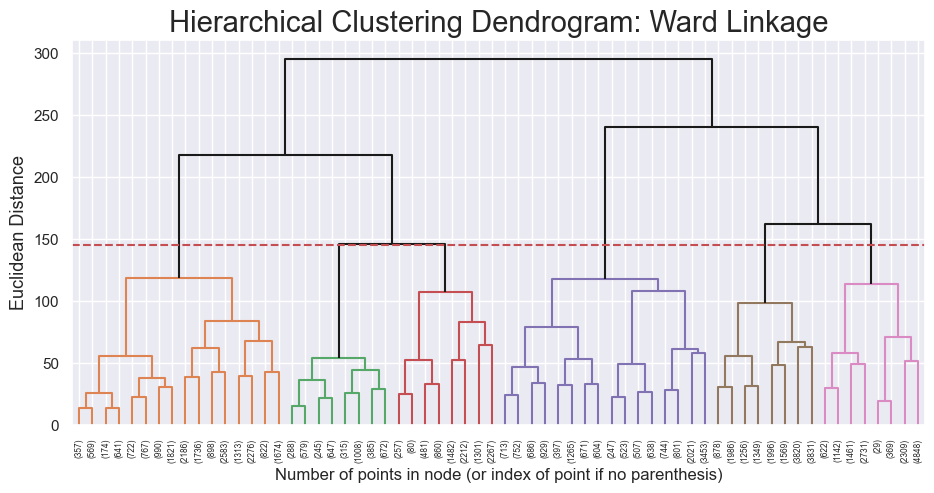

In [ ]:
# Plot the corresponding dendrogram
sns.set()
fig = plt.figure(figsize=(11,5))
# The Dendrogram parameters need to be tuned
y_threshold = 170
dendrogram(linkage_matrix, truncate_mode='level', p=5, color_threshold=y_threshold, above_threshold_color='k')
plt.hlines(y_threshold, 0, 1000, colors="r", linestyles="dashed")
plt.title(f'Hierarchical Clustering Dendrogram: {linkage.title()} Linkage', fontsize=21)
plt.xlabel('Number of points in node (or index of point if no parenthesis)')
plt.ylabel(f'{distance.title()} Distance', fontsize=13)
plt.show()

From the hierarchical clustering we can see that either 4 or 6 clusters could be chosen, nonetheless we decided to go with 4 instead of 6 to obtain clusters that are more balanced in terms of size. As the Hierarchical clustering is fairly slow in large datasets and having in mind that we want our customer segmentation to be easily scalable, we only used this hierarchical clustering dendrogram to know the initial number of clusters and then we will use the K-Means with that specific number of clusters. <br>

Additionally, K-Means is preferable as it can reassign the cluster assigned to each customer, while in hierarchical when group in the cluster individuals cannot be divided again, they are glowed together until the end of the clustering process.

__`Step 48`__ Perform the K-Means clustering with 4 clusters

In [74]:
# Apply KMeans clustering
kmeans2 = KMeans(n_clusters=4, init='k-means++', n_init=15, random_state=90)
labels2 = kmeans2.fit_predict(df_impute[clustering_features])

__`Step 48.1`__ Check the centroids of the clustering solution

In [75]:
Centroids = pd.DataFrame(kmeans2.cluster_centers_.round(2), columns=df_impute[clustering_features].columns)

# Print the DataFrame
print(tabulate(Centroids, headers='keys', tablefmt='pretty', showindex=True))
stats = Centroids.describe().iloc[[1,2,3,7]]
minmax_diff = stats.iloc[3]-stats.iloc[2]
stats.loc['minmax_differences'] = minmax_diff
print(stats)

+---+-------+-------------------+-----------------+----------------------+----------------+-------------------------+----------------------------+-----------+
|   |  Age  | DaysSinceCreation | AverageLeadTime | TotalSpecialRequests | RevenuePerStay | PersonsNightsPerBooking | RevenuePerDaySinceCreation | AvgIncome |
+---+-------+-------------------+-----------------+----------------------+----------------+-------------------------+----------------------------+-----------+
| 0 | 0.98  |       -0.0        |      1.43       |         0.14         |     -0.06      |          -0.1           |           -0.06            |   0.42    |
| 1 | -0.15 |       0.69        |      -0.44      |        -0.18         |     -0.66      |          -0.48          |           -0.91            |   -0.24   |
| 2 | -0.09 |       -0.08       |      0.11       |         0.33         |      1.29      |          1.47           |            0.84            |   -0.1    |
| 3 | -0.35 |       -0.93       |      -0.34  

Based on the clusters centroids we get to the following cluster names:

- Cluster 0: Retired
    - Older guests (higher Age score)
    - Book well in advance (high AverageLeadTime)
    - Moderate special requests
    - Low revenue per stay and per day
    - Likely retirees or cautious planners who prefer early bookings and longer stays at lower budgets

- Cluster 1: Pioneering Tourists
    - Younger guests (lower Age score)
    - Book at the last minute (negative AverageLeadTime)
    - They have been with the business for a longer period
    - Low revenue per stay and per day
    - Fewer special requests
    - Likely young budget travelers or backpackers making spontaneous bookings

- Cluster 2: Luxury Long Stayers
    - Moderate age
    - High revenue per stay and per day
    - High special requests
    - More persons per booking, indicating family or group travelers
    - Likely luxury vacationers or large groups staying for extended periods

- Cluster 3: Fresh-Faced Customers
    - Younger guests with the lowest planning time
    - Moderate revenue per stay but high revenue per day
    - Few special requests
    - Likely business travelers or short-stay guests booking at the last minute

__`Step 49`__ Comparing the 4 clusters solutions against the 2 cluster solution using K-Means.

In [79]:
# Creating a contingency table
contingency_table = pd.crosstab(labels, labels2, colnames=['4 Clusters'], rownames=['2 Clusters'])

# Display the contingency table
print("Contingency Table for 2 Clusters vs. 4 Clusters:")
print(contingency_table)

Contingency Table for 2 Clusters vs. 4 Clusters:
4 Clusters     0      1      2      3
2 Clusters                           
0           6111  28846    660   4619
1           6505     24  12967  15549


From this contingency table, we observe that both the 2-cluster and 4-cluster solutions result in relatively similar overall segment sizes. However, the 4-cluster solution proves to be the superior choice as it maintains a balanced distribution while capturing a greater diversity of customer behaviors and segment sizes. This variation is expected, as a hotel would naturally have different proportions of retired customers compared to high-value or frequent guests. For these reasons, the 4-cluster solution was selected as the final segmentation model, offering a more nuanced and actionable understanding of the customer base.

__`Step 50`__ Put the labels of the clusters into the dataset.

In [96]:
df_impute['Customer Segments_number'] = labels2

__`Step 50.1`__ Changing the labels of the clusters from numbers into the name we gave them.

In [97]:
# Define a mapping of cluster labels to their names
cluster_names = {
    0: "Retired",
    1: "Free Souls",
    2: "Star customers",
    3: "Businessman"}

# Replace the numerical labels with the cluster names
df_impute['Customer Segments'] = df_impute['Customer Segments_number'].map(cluster_names)

# 5. Evaluation

## 5.1. Profilling

__`Step 51`__ Create a function to perform the graph that will be used for profiling the clusters.

In [98]:
def cluster_profile(df, label_column, figsize=(12, 6), cmap="tab10", title="Cluster Profiling"):
    """
    Generates a cluster profile visualization for a single clustering label.

    Parameters:
    - df: DataFrame containing the data.
    - label_column: The name of the column representing cluster labels.
    - figsize: Tuple specifying the figure size (width, height).
    - cmap: Color palette for visualization.
    - title: Title for the overall plot.
    """
    
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=figsize, constrained_layout=True)
    
    # Getting the cluster centroids and counts
    centroids = df.groupby(by=label_column, as_index=False).mean()
    counts = df[label_column].value_counts().reset_index()
    counts.columns = [label_column, "counts"]

    # Parallel Coordinates Plot (Cluster Means)
    pd.plotting.parallel_coordinates(centroids, 
                                     class_column=label_column, 
                                     color=sns.color_palette(cmap), 
                                     ax=axes[0])

    axes[0].axhline(y=0, color="black", linestyle="--")
    axes[0].set_title(f"Cluster Means - {len(counts)} Clusters", fontsize=13)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=40, ha='right')

    # Legend
    handles, _ = axes[0].get_legend_handles_labels()
    cluster_labels = [f"Cluster {i}" for i in range(len(handles))]
    axes[0].legend(handles, cluster_labels, loc='center left', bbox_to_anchor=(1, 0.5), title=label_column)

    # Bar Plot (Cluster Sizes)
    sns.barplot(x=label_column, y="counts", data=counts, ax=axes[1], palette=sns.color_palette(cmap))

    axes[1].set_xticklabels(cluster_labels)
    axes[1].set_xlabel("")
    axes[1].set_ylabel("Absolute Frequency")
    axes[1].set_title(f"Cluster Sizes - {len(counts)} Clusters", fontsize=13)

    # Overall title
    plt.suptitle(title, fontsize=20)

    # Save the figure
    plt.savefig('cluster_profile.png', dpi=300, bbox_inches='tight')

    # Show the figure
    plt.show()

__`Step 51.1`__ Apply the function to make the analysis of the clusters.

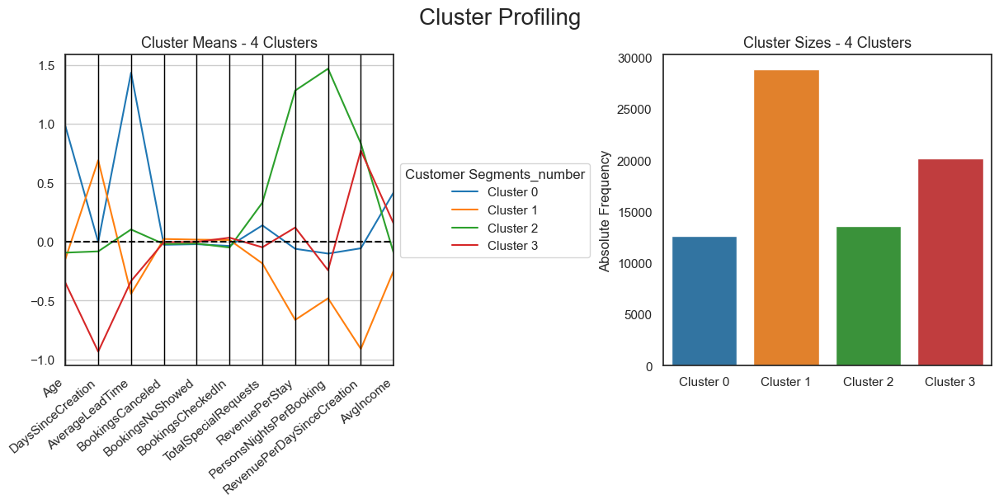

In [99]:
cluster_profile(df_impute[numerical_features + ['Customer Segments_number']], label_column="Customer Segments_number", figsize=(12, 6))

From this profiling analysis, we observe clear separations in numerical feature values across customer segments, further validating the effectiveness of our feature engineering process. The newly created features successfully highlight distinct differences between segments, reinforcing the quality of our clustering approach.

On the other hand, features that were not used for clustering—such as those related to booking cancellations, show rates, and check-ins—did not exhibit significant variation across clusters.

Overall, these results indicate that our clustering algorithm performed well, as the segments display meaningful distinctions based on the selected features. (For a comprehensive analysis of this graph, please refer to the full report.)

__`Step 52`__ Make the profiling of the clusters based on the feature `DistributionChannel`.

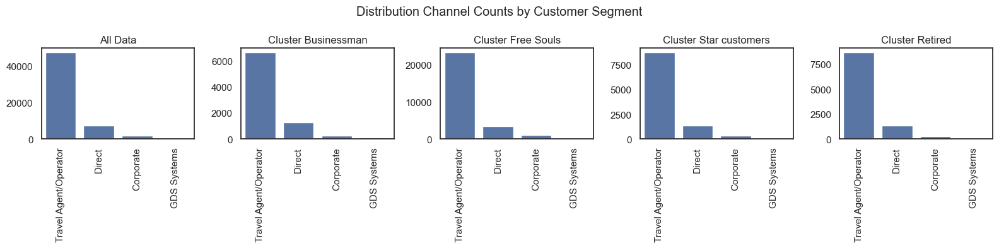

In [100]:
# Create subplots (one for all data + one for each cluster)
fig, axes = plt.subplots(1, 
                         df_impute['Customer Segments'].nunique() + 1,  # Number of clusters + 1 for overall data
                         figsize=(16, 4),
                         tight_layout=True)

# Loop through the axes to plot the countplots
for i in range(len(axes.flatten())): 
    ax = axes[i]
    
    if i == 0:
        # Overall distribution
        sns.countplot(data=df_impute, 
                      x='DistributionChannel', 
                      order=df_impute['DistributionChannel'].value_counts().index, 
                      ax=ax)
        ax.set_title("All Data")
        
    else:    
        # Per-cluster distribution
        cluster_label = df_impute['Customer Segments'].unique()[i-1]  # Get correct cluster label
        sns.countplot(data=df_impute[df_impute['Customer Segments'] == cluster_label], 
                      x='DistributionChannel', 
                      order=df_impute['DistributionChannel'].value_counts().index, 
                      ax=ax)
        ax.set_title(f"Cluster {cluster_label}")
    
    ax.tick_params(axis="x", labelrotation=90)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle("Distribution Channel Counts by Customer Segment")
plt.show()

From this graph we can't see any worth mentioning difference between clustering compared to what distribution channel they used.

__`Step 53`__ Make the profiling of the clusters based on the feature `Nationality`.

  Customer Segments Nationality  count
0       Businessman         AUS     71
1       Businessman         AUT    118
2       Businessman         BEL    317
3       Businessman         BRA    308
4       Businessman         CAN    175


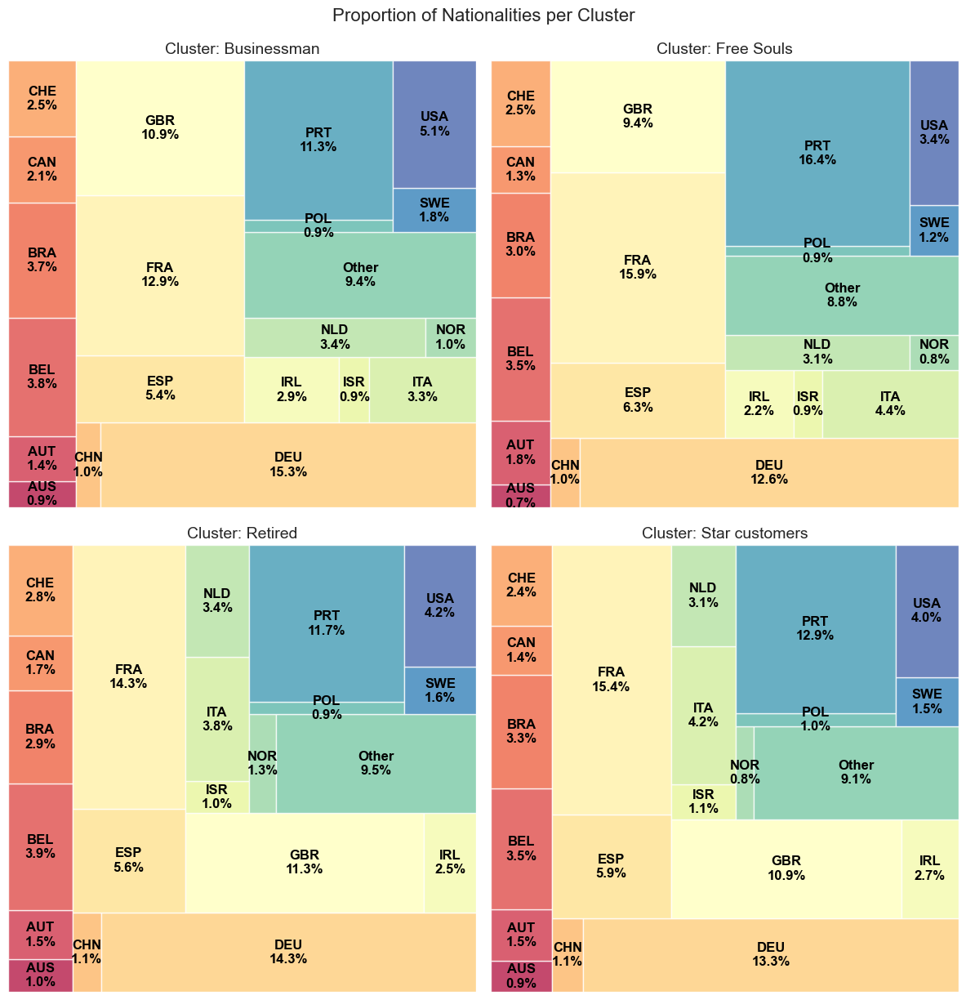

In [101]:
# Group data by 'Customer Segments' (clusters) and 'Nationality' to get the counts
grouped_data = df_impute.groupby(['Customer Segments', 'Nationality']).size().reset_index(name='count')

# Check the first few rows of the grouped data
print(grouped_data.head())

# Set up the figure for 4 small multiples (2 rows, 2 columns)
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

# Loop over the unique Customer Segments (clusters)
for cluster_idx, cluster in enumerate(grouped_data['Customer Segments'].unique()):
    # Filter data for the current cluster
    cluster_data = grouped_data[grouped_data['Customer Segments'] == cluster]
    
    # Check if the filtered data is empty
    if cluster_data.empty:
        print(f"Cluster '{cluster}' has no data!")
        continue  # Skip the cluster if there's no data
    
    # Calculate the proportion of each nationality within the cluster
    total_count = cluster_data['count'].sum()  # Total count for the current cluster
    
    # Avoid division by zero or NaN issues
    if total_count == 0:
        print(f"Total count for Cluster '{cluster}' is zero!")
        continue
    
    cluster_data['proportion'] = cluster_data['count'] / total_count  # Proportion of each nationality
    
    # Set the sizes and labels
    sizes = cluster_data['proportion'].values
    labels = cluster_data['Nationality'].values
    
    # Ensure there are non-zero sizes
    if sizes.sum() == 0:
        print(f"Cluster '{cluster}' has zero-sized categories!")
        continue
    
    # Use a color palette for each cluster
    colors = sns.color_palette("Spectral", len(cluster_data))
    
    # Plot each treemap in the respective subplot
    ax = axes[cluster_idx // 2, cluster_idx % 2]  # Determine position in the grid
    squarify.plot(sizes=sizes, label=[f"{label}\n{round(val * 100, 1)}%" for label, val in zip(labels, sizes)], 
                  ax=ax, color=colors, alpha=0.8, text_kwargs={'fontsize': 12, 'color': 'black', 'weight': 'bold'})
    
    # Title and axis labels
    ax.set_title(f'Cluster: {cluster}', fontsize=14)
    ax.axis('off')  # Turn off axis lines

# Adjust layout for clarity
plt.tight_layout()
plt.suptitle("Proportion of Nationalities per Cluster", fontsize=16, y=1.02)
plt.show()


From these Nationality tree maps we can't see major differences between clusters, they seem pretty equal.

__`Step 54`__ Using a contigency table to check the main differences between the old and the new market segments.

In [102]:
# Creating the contingency table
contingency_table = pd.crosstab(df_impute['Customer Segments'], df_impute['MarketSegment'], 
                                colnames=['Old Market Segments'], rownames=['New Market Segments'])

# Display the contingency table with formatted numbers
print("Contingency Table for Old vs. New Market Segmentation:")
print(contingency_table.to_string(formatters={'Aviation': '{:,.0f}'.format,
                                              'Complementary': '{:,.0f}'.format,
                                              'Corporate': '{:,.0f}'.format,
                                              'Direct': '{:,.0f}'.format,
                                              'Groups': '{:,.0f}'.format,
                                              'Other': '{:,.0f}'.format,
                                              'Travel Agent/Operator': '{:,.0f}'.format}))

Contingency Table for Old vs. New Market Segmentation:
Old Market Segments Aviation Complementary Corporate Direct Groups  Other Travel Agent/Operator
New Market Segments                                                                            
Businessman               25            57       288  1,216    977  4,441                 1,234
Free Souls                96           137       717  3,253  3,438 15,900                 4,303
Retired                   26            39       243  1,278  1,128  5,977                 1,696
Star customers            37            44       293  1,305  1,255  5,907                 1,621


Comparing the previous clusters to the new ones, we can see that the updated clustering solution is significantly better, as it produces more balanced segment sizes. This refined segmentation ensures that clusters are less broad while avoiding overly narrow niche groups that may not justify dedicated marketing investments. As a result, the new customer segmentation provides a more practical and effective framework for targeted marketing strategies, optimizing resource allocation and engagement potential.

## 5.2 Cluster Visualization

__`Step 55`__ Visualizing the clusters using t-SNE.

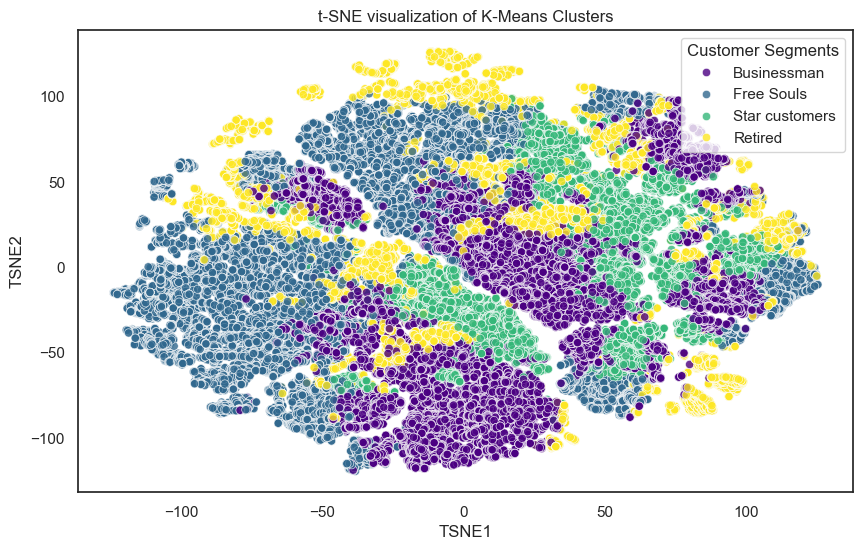

In [103]:
# Define a custom color palette
custom_palette = {
    "Businessman": "#4B0082",
    "Free Souls": "#31688E",
    "Star customers": "#35B779",
    "Retired": "#FDE725"
}

# Apply t-SNE for dimensionality reduction (2D visualization)
tsne = TSNE(n_components=2, random_state=90)
df_impute['TSNE1'], df_impute['TSNE2'] = tsne.fit_transform(df_impute[clustering_features]).T

# Visualizing the clusters with t-SNE
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='TSNE1', y='TSNE2', hue='Customer Segments', palette=custom_palette, data=df_impute, alpha=0.8
)
plt.title('t-SNE visualization of K-Means Clusters')
plt.show()

The t-SNE visualization provides a two-dimensional representation of the high-dimensional customer segmentation data, allowing us to assess the quality of the clustering process.

**Evaluation of Cluster Separation**
- The clusters exhibit a **reasonable degree of separation**, indicating that the K-Means algorithm successfully identified meaningful customer segments.
- While some **overlapping regions exist**, particularly between the *Free Souls* (blue) and *Star Customers* (green), the clusters generally display distinct groupings.
- The *Businessman* (purple) and *Retired* (yellow) segments are more concentrated in specific areas, suggesting strong differentiation from other groups.

**Insights and Considerations**
- The relatively **well-balanced distribution** of clusters supports the robustness of the segmentation model, avoiding extreme imbalances.
- Overlapping areas may indicate **shared behavioral traits** between segments, which could be further refined through additional features or alternative clustering techniques.


**Next Steps**
- **Feature enhancement:** Investigate whether additional behavioral or demographic features can improve cluster separability.
- **Alternative clustering approaches:** Experiment with different clustering algorithms (e.g., DBSCAN, Self-Organizing Map) to explore potential improvements in segmentation.

Overall, the t-SNE visualization confirms that the K-Means clustering model has effectively identified distinct customer segments, offering valuable insights for targeted marketing and business strategies.

# 6. Deployment

With clearly defined customer segments, we are shifting from a generic approach to a targeted marketing strategy. This ensures higher efficiency, better customer engagement, and optimized marketing spending by addressing what each group values most.  

**1. Retired (Comfort & Reliability)**  
- **Loyalty Rewards** → Special deals for repeat customers to encourage long-term engagement.  
- **Next-Stay Vouchers** → Discounts for future bookings when reserved before checkout.  
- **Traditional Communication** → Email newsletters and direct mail for effective outreach.  

**Monitoring & Maintenance:**  
The CRM team tracks voucher redemptions, the communications team manages engagement, and reception staff introduces loyalty offers at checkout.  

**2. Free Souls (Spontaneity & Flexibility)**  
- **Flash Sales & Urgent Deals** → Real-time last-minute discounts via mobile notifications.  
- **"Book Now, Pay Later" Flexibility** → Payments upon arrival to reduce hesitation.  
- **Social Media Incentives** → Rewards for sharing their stay on Instagram.  
- **Longer Stay Discounts** → Exclusive rates to encourage extended stays.  

**Monitoring & Maintenance:**  
Digital marketing analyzes engagement, social media tracks user-generated content, and reservations manage flexible payments.  

**3. Star Customers (Exclusive & Premium Experience)**  
- **Personalized Concierge Service** → Priority check-ins and dedicated assistance.  
- **Exclusive Membership Perks** → Discounts on spa, private dining, and chauffeur services.  
- **Tailored Welcome & Stay Experience** → Personalized room preferences and amenities.  

**Monitoring & Maintenance:**  
Guest relations track VIP retention, hotel staff receive specialized training, and feedback is collected to refine the luxury experience.  

**4. Businessman of the World (Efficiency & Convenience)**  
- **Business-Focused Upgrades** → Lounge access, express check-in, premium Wi-Fi.  
- **Loyalty Program for Frequent Stays** → Room upgrades after three stays.  
- **Personalized Offers via App & Email** → Meeting spaces, gym access, and airport transfers.  

**Monitoring & Maintenance:**  
Marketing tracks repeat bookings, IT ensures seamless app/email targeting, and operations oversee business service usage and feedback.  

This targeted strategy enhances engagement, increases retention, and optimizes revenue by delivering personalized experiences tailored to each customer segment.